# КРР по mOTU — единый пайплайн на логистической регрессии

Объединение `final_solution_1.ipynb` (модель/валидация) и `genotek_catboost_ebm.ipynb` (очистка/исследования).
**Единственная модель — L2-логистическая регрессия** (`log10`, встречаемость ≥ 3 %, genus-агрегаты, бинарные флаги, `C=0.004`).

| Блок | Содержание |
| - | - |
| 0 | Окружение и константы |
| 1 | Загрузка и очистка данных |
| 2 | Признаки и модель (всё обучается внутри фолда) |
| 3 | Валидация 5×5 + LOCO, обучение, сабмит |
| 4 | **Пороги: confusion matrix, TP/FP/TN/FN, клинический выбор** |
| 5 | Исследования: коэффициенты, ассоциации, разнообразие, PERMANOVA, абляции, разбор ошибок |
| 6 | Финальное обучение, файлы, версии |

Ключевой принцип медицины: **порог 0.5 не является нейтральным**. Сильная L2-регуляризация сжимает вероятности к базовой доле класса, поэтому 0.5 систематически занижает чувствительность. Порог выбирается по цене ошибки (FN ≫ FP), фиксируется на OOF и **честно проверяется на отложенных когортах (LOCO)**.

In [1]:
from importlib.metadata import version
import re, sys, warnings
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.spatial.distance import cdist
from scipy.special import expit
from scipy.stats import mannwhitneyu, spearmanr, false_discovery_control

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

warnings.filterwarnings('ignore')

SEED = 42
N_SPLITS = 5
N_REPEATS = 5
MIN_PREVALENCE = 0.03      # порог встречаемости mOTU (внутри фолда)
LOG_EPS = 1e-5             # псевдосчёт для log10
BEST_C = 0.004             # сила L2 из отбора в final_solution_1
N_PERM = 999
N_BOOT = 2000

# Клинические настройки: цена пропущенного рака относительно ложной тревоги
COST_FN, COST_FP = 10.0, 1.0
TARGET_SENS = 0.95         # скрининг: правило "исключить" (rule-out)
TARGET_SPEC = 0.90         # подтверждение: правило "направить" (rule-in)

GROUP_NAMES = {0: 'Контроль', 1: 'КРР'}
CLASS_COLORS = {'Контроль': '#356FA3', 'КРР': '#BE4B5E'}

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10,
                     'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9})
pd.set_option('display.width', 160, 'display.max_columns', 60)

def lim():
    return threadpool_limits(limits=1) if threadpool_limits is not None else nullcontext()

print('Python', sys.version.split()[0])

Python 3.13.5


## Блок 1. Загрузка и очистка

Что делаем и почему:
- mOTU-колонки узнаём по суффиксу `[mOTU...]`; проверяем NaN/inf/отрицательные значения;
- доли **не перенормируем** для модели (как в лучшей конфигурации `L2_log10_p03_C004_bin`), но делаем нормированную копию для Bray–Curtis и альфа-разнообразия;
- `bmi` заполняем медианой по `(cohort, gender)`, посчитанной **только по train**, и добавляем флаг пропуска;
- `library_size` — технический шум секвенирования: в модель не берём, используем как ковариатуру в исследованиях;
- `cohort` в модель не берём: модель должна переноситься на новую когорту (проверка LOCO).

In [2]:
train = pd.read_csv('train.csv').reset_index(drop=True)
test = pd.read_csv('test.csv').reset_index(drop=True)

MOTU_SUFFIX = re.compile(r'\[[^\[\]]+\]\s*$')
bac_cols = [c for c in train.columns if MOTU_SUFFIX.search(c)]
assert len(bac_cols) > 0, 'Не найдено ни одной mOTU-колонки'
assert set(bac_cols).issubset(test.columns), 'Набор mOTU в train и test различается'
assert train['sample_id'].is_unique and test['sample_id'].is_unique
assert set(train['label'].unique()) <= {0, 1}

cohort_names = sorted(train['cohort'].unique())
print(f'train: {len(train)} образцов, {len(bac_cols)} mOTU, {len(cohort_names)} когорт')
print(f'test:  {len(test)} образцов')
print('Служебные колонки:', [c for c in train.columns if c not in bac_cols])
print('Пример mOTU-колонки:', bac_cols[0])

train: 415 образцов, 849 mOTU, 5 когорт
test:  160 образцов
Служебные колонки: ['sample_id', 'label', 'cohort', 'age', 'gender', 'bmi', 'library_size']
Пример mOTU-колонки: Clostridium saccharogumia [ref_mOTU_v2_0473]


In [3]:
def clean_taxa(df, cols):
    x = df[cols].apply(pd.to_numeric, errors='coerce')
    report = {'NaN': int(x.isna().sum().sum()),
              'inf': int(np.isinf(x.to_numpy(dtype=float)).sum()),
              'отрицательных': int((x < 0).sum().sum())}
    x = x.replace([np.inf, -np.inf], np.nan).clip(lower=0).fillna(0.0)
    return x, report

train_taxa, rep_tr = clean_taxa(train, bac_cols)
test_taxa, rep_te = clean_taxa(test, bac_cols)
train[bac_cols] = train_taxa
test[bac_cols] = test_taxa
print('Очистка mOTU train:', rep_tr)
print('Очистка mOTU test: ', rep_te)

# Нормированная копия — только для описательной экологии (Bray-Curtis, альфа-разнообразие)
train_rel = train[bac_cols].div(train[bac_cols].sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)
test_rel = test[bac_cols].div(test[bac_cols].sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)

sums = train[bac_cols].sum(axis=1)
print(f'Суммы долей mOTU в образце: {sums.min():.4f} … {sums.max():.4f} (медиана {sums.median():.4f})')
print('Ненормированность — причина, по которой экология считается на train_rel, а модель на исходных долях.')

dup_rows = int(train[bac_cols].duplicated().sum())
print(f'Полных дублей профиля mOTU в train: {dup_rows}. ID пациента нет, повторные образцы одного человека исключить нельзя.')

Очистка mOTU train: {'NaN': 0, 'inf': 0, 'отрицательных': 0}
Очистка mOTU test:  {'NaN': 0, 'inf': 0, 'отрицательных': 0}
Суммы долей mOTU в образце: 0.5681 … 0.9957 (медиана 0.9666)
Ненормированность — причина, по которой экология считается на train_rel, а модель на исходных долях.
Полных дублей профиля mOTU в train: 0. ID пациента нет, повторные образцы одного человека исключить нельзя.


In [4]:
# Метаданные: типы, аномалии, пропуски
for col in ['age', 'bmi', 'library_size']:
    if col in train.columns:
        for df in (train, test):
            df[col] = pd.to_numeric(df[col], errors='coerce')

if 'age' in train.columns:
    for df in (train, test):
        df.loc[(df['age'] <= 0) | (df['age'] > 120), 'age'] = np.nan
if 'bmi' in train.columns:
    for df in (train, test):
        df.loc[(df['bmi'] < 10) | (df['bmi'] > 70), 'bmi'] = np.nan
for df in (train, test):
    df['gender'] = df['gender'].astype(str).str.strip().str.upper().where(
        df['gender'].astype(str).str.strip().str.upper().isin(['M', 'F']), 'NA')

print('Пропуски метаданных до заполнения:')
display(train.groupby('label')[[c for c in ['age', 'bmi', 'library_size'] if c in train.columns]]
        .agg(lambda s: int(s.isna().sum())).rename(index=GROUP_NAMES))

# BMI: медиана по (cohort, gender) считается ТОЛЬКО по train
if 'bmi' in train.columns:
    bmi_medians = train.groupby(['cohort', 'gender'])['bmi'].median().to_dict()
    global_bmi = float(train['bmi'].median())
    for df in (train, test):
        df['bmi_missing'] = df['bmi'].isna().astype(int)
        fill = [bmi_medians.get(k, global_bmi) for k in zip(df['cohort'], df['gender'])]
        df['bmi'] = df['bmi'].fillna(pd.Series(fill, index=df.index))
    print(f'Заполнено BMI: train {int(train["bmi_missing"].sum())}, test {int(test["bmi_missing"].sum())}')

for df in (train, test):
    if 'library_size' in df.columns:
        df['log10_library_size'] = np.log10(df['library_size'].clip(lower=1))

meta_num = [c for c in ['age', 'bmi', 'log10_library_size'] if c in train.columns]
meta_cat = ['gender']
print('Ковариатуры для исследований:', meta_num + meta_cat)

Пропуски метаданных до заполнения:


,age,bmi,library_size
label,,,
Контроль,0,0,0
КРР,0,3,0


Заполнено BMI: train 3, test 5
Ковариатуры для исследований: ['age', 'bmi', 'log10_library_size', 'gender']


In [5]:
y = train['label'].to_numpy(dtype=int)
cohorts = train['cohort'].to_numpy()

balance = pd.DataFrame({
    'train n': train['cohort'].value_counts(),
    'train доля': train['cohort'].value_counts(normalize=True).round(3),
    'test n': test['cohort'].value_counts(),
    'test доля': test['cohort'].value_counts(normalize=True).round(3),
    'КРР в train': train.groupby('cohort')['label'].sum(),
    'доля КРР train': train.groupby('cohort')['label'].mean().round(3),
}).loc[cohort_names]
display(balance)
print(f'Общая доля КРР в train: {y.mean():.3f}  (база для AP и для порога)')

prev_all = (train[bac_cols] > 0).mean()
print('\nСколько mOTU проходит порог встречаемости:')
for thr in [0.02, 0.03, 0.05, 0.10, 0.15]:
    print(f'  >= {int(thr*100):2d}%: {int((prev_all >= thr).sum())} из {len(bac_cols)}')

# Оральная панель (описательно; в модель отдельным признаком не добавляем)
ORAL_SPECIES = ['Fusobacterium nucleatum', 'Parvimonas micra', 'Peptostreptococcus stomatis',
                'Porphyromonas asaccharolytica', 'Solobacterium moorei', 'Gemella morbillorum',
                'Streptococcus anginosus']
def taxon_name(c):
    return c.split(' [')[0].strip()
oral_cols = [c for c in bac_cols if any(taxon_name(c).startswith(s) for s in ORAL_SPECIES)]
print(f'\nОральная панель: найдено {len(oral_cols)} mOTU (подвиды F. nucleatum считаются отдельно)')
for c in oral_cols:
    print(f'  {taxon_name(c):45s} встречаемость {prev_all[c]:.3f}')
train['oral_total'] = train[oral_cols].sum(axis=1) if oral_cols else 0.0
train['oral_count'] = (train[oral_cols] > 0).sum(axis=1) if oral_cols else 0
test['oral_total'] = test[oral_cols].sum(axis=1) if oral_cols else 0.0
test['oral_count'] = (test[oral_cols] > 0).sum(axis=1) if oral_cols else 0

,train n,train доля,test n,test доля,КРР в train,доля КРР train
cohort,,,,,,
AUS,79,0.190,30,0.188,31,0.392
CHI,99,0.239,29,0.181,58,0.586
FRA,80,0.193,34,0.212,37,0.462
GER,87,0.210,33,0.206,43,0.494
USA,70,0.169,34,0.212,36,0.514


Общая доля КРР в train: 0.494  (база для AP и для порога)

Сколько mOTU проходит порог встречаемости:
  >=  2%: 802 из 849
  >=  3%: 762 из 849
  >=  5%: 681 из 849
  >= 10%: 546 из 849
  >= 15%: 452 из 849

Оральная панель: найдено 11 mOTU (подвиды F. nucleatum считаются отдельно)
  Fusobacterium nucleatum s. vincentii          встречаемость 0.087
  Fusobacterium nucleatum s. animalis           встречаемость 0.231
  Fusobacterium nucleatum s. nucleatum          встречаемость 0.070
  Streptococcus anginosus                       встречаемость 0.340
  Streptococcus anginosus                       встречаемость 0.140
  Streptococcus anginosus                       встречаемость 0.333
  Peptostreptococcus stomatis                   встречаемость 0.294
  Gemella morbillorum                           встречаемость 0.381
  Parvimonas micra                              встречаемость 0.400
  Porphyromonas asaccharolytica                 встречаемость 0.128
  Solobacterium moorei               

## Блок 2. Признаки и модель

`TaxaFeatures` — трансформер, который **обучается внутри фолда** (никакой утечки):
1. отбор mOTU по встречаемости ≥ 3 % на обучающей части;
2. `log10(x + 1e-5)` (сглаживает тяжёлый правый хвост долей);
3. агрегаты по родам (сумма исходных долей рода → тот же логарифм), только роды с ≥ 2 mOTU;
4. бинарные флаги обнаружения `x > 0` (ловят эффект «есть/нет», который логарифм размывает);
5. `StandardScaler` → `LogisticRegression(C=0.004, L2)`.

Метаданные и когорта в модель не входят: `library_size` — техника, `cohort` — источник сдвига, а не биология.

In [6]:
def genus_of(col):
    name = taxon_name(col)
    return name.split()[0] if name else 'NA'


class TaxaFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, bac_cols, min_prevalence=0.03, method='log10', eps=1e-5,
                 add_genus=True, add_binary=True, binary_thr=0.0, renormalize=False):
        self.bac_cols = bac_cols
        self.min_prevalence = min_prevalence
        self.method = method
        self.eps = eps
        self.add_genus = add_genus
        self.add_binary = add_binary
        self.binary_thr = binary_thr
        self.renormalize = renormalize

    def _raw(self, X):
        raw = X[self.bac_cols].to_numpy(dtype=float, copy=True)
        raw = np.clip(np.nan_to_num(raw, nan=0.0, posinf=0.0, neginf=0.0), 0.0, None)
        if self.renormalize:
            raw = raw / np.maximum(raw.sum(axis=1, keepdims=True), 1e-12)
        return raw

    def fit(self, X, y=None):
        raw = self._raw(X)
        prev = (raw > 0).mean(axis=0)
        pos = {c: i for i, c in enumerate(self.bac_cols)}
        self.selected_cols_ = [c for c, p in zip(self.bac_cols, prev) if p >= self.min_prevalence]
        if not self.selected_cols_:
            raise ValueError('Ни один mOTU не прошёл порог встречаемости')
        self.sel_idx_ = np.array([pos[c] for c in self.selected_cols_], dtype=int)
        self.genus_groups_ = {}
        if self.add_genus:
            tmp = {}
            for j, c in enumerate(self.selected_cols_):
                tmp.setdefault(genus_of(c), []).append(j)
            self.genus_groups_ = {g: js for g, js in tmp.items() if len(js) >= 2}
        names = list(self.selected_cols_) + [f'genus::{g}' for g in self.genus_groups_]
        if self.add_binary:
            names += [f'bin::{c}' for c in self.selected_cols_]
        self.feature_names_out_ = np.asarray(names, dtype=object)
        return self

    def _map(self, v):
        if self.method == 'log10':
            return np.log10(v + self.eps)
        if self.method == 'sqrt':
            return np.sqrt(v)
        if self.method == 'clr':
            lv = np.log(v + self.eps)
            return lv - lv.mean(axis=1, keepdims=True)
        if self.method == 'raw':
            return v
        raise ValueError(self.method)

    def transform(self, X):
        raw = self._raw(X)[:, self.sel_idx_]
        blocks = [self._map(raw)]
        if self.genus_groups_:
            g = np.column_stack([raw[:, js].sum(axis=1) for js in self.genus_groups_.values()])
            blocks.append(self._map(g))
        if self.add_binary:
            blocks.append((raw > self.binary_thr).astype(float))
        return np.hstack(blocks)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_


def make_l2_pipeline(bac_cols, C=BEST_C, min_prevalence=MIN_PREVALENCE, method='log10',
                     add_genus=True, add_binary=True, scale=True, **kw):
    steps = [('taxa', TaxaFeatures(bac_cols, min_prevalence=min_prevalence, method=method,
                                   add_genus=add_genus, add_binary=add_binary,
                                   eps=LOG_EPS, **kw))]
    if scale:
        steps.append(('scale', StandardScaler()))
    steps.append(('clf', LogisticRegression(C=C, solver='lbfgs', max_iter=5000, random_state=SEED)))
    return Pipeline(steps)


_probe = make_l2_pipeline(bac_cols).fit(train, y)
print('Признаков после отбора/агрегации на всём train:', len(_probe[:-1].get_feature_names_out()))
print('  mOTU:', len(_probe[0].selected_cols_), '| родов:', len(_probe[0].genus_groups_),
      '| бинарных:', len(_probe[0].selected_cols_))
del _probe

Признаков после отбора/агрегации на всём train: 1575
  mOTU: 762 | родов: 51 | бинарных: 762


## Блок 3. Валидация и обучение

- **5×5 StratifiedKFold** по ключу `label + cohort + gender` — «новые образцы из знакомых когорт».
- **LOCO (LeaveOneGroupOut по когорте)** — «новая когорты целиком», главный тест переносимости.
- `per_cohort_auc` — средний AUROC внутри когорт (без межкогортных сравнений).
- `oof_auc` по объединённым OOF включает межкогортные пары — это оптимистичная величина, смотрим на неё вместе с LOCO.

Сабмит — усреднение вероятностей по 25 фолдам (`sub_best_l2_bin.csv`).

In [7]:
strat_key = (train['label'].astype(str) + '_' + train['cohort'].astype(str) + '_' + train['gender'].astype(str))
vc = strat_key.value_counts()
if vc.min() < N_SPLITS:
    print(f'Мелкая страта ({vc.min()} < {N_SPLITS}), откатываемся к label + cohort')
    strat_key = train['label'].astype(str) + '_' + train['cohort'].astype(str)
print('Минимальный размер страты:', strat_key.value_counts().min())

splits_5x5 = []
for rep in range(N_REPEATS):
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED + rep * 17)
    splits_5x5.append(list(skf.split(train, strat_key)))
loco_splits = list(LeaveOneGroupOut().split(train, y, groups=cohorts))

rows = []
for fold, (_, va) in enumerate(splits_5x5[0], 1):
    sub = train.iloc[va]
    rows.append({'fold': fold, 'n': len(sub), 'доля КРР': round(sub['label'].mean(), 3),
                 'когорты': sub['cohort'].value_counts().to_dict()})
display(pd.DataFrame(rows))
print('LOCO-фолдов:', len(loco_splits))

Минимальный размер страты: 5


,fold,n,доля КРР,когорты
0,1,83,0.482,"{'CHI': 19, 'GER': 18, 'FRA': 16, 'AUS': 16, '..."
1,2,83,0.494,"{'CHI': 20, 'GER': 17, 'FRA': 17, 'AUS': 16, '..."
2,3,83,0.494,"{'CHI': 21, 'GER': 17, 'AUS': 16, 'FRA': 15, '..."
3,4,83,0.506,"{'CHI': 20, 'GER': 18, 'FRA': 16, 'AUS': 15, '..."
4,5,83,0.494,"{'CHI': 19, 'GER': 17, 'FRA': 16, 'AUS': 16, '..."


LOCO-фолдов: 5


In [8]:
def per_cohort_auc(y_true, preds, cohorts_arr):
    aucs = []
    for c in pd.unique(cohorts_arr):
        mask = (cohorts_arr == c)
        if len(np.unique(y_true[mask])) == 2:
            aucs.append(roc_auc_score(y_true[mask], preds[mask]))
    return float(np.mean(aucs))


rep_oofs, rep_aucs, fold_aucs = [], [], []
test_preds = np.zeros(len(test))
coef_bank, fold_records = [], []

with lim():
    for rep_id, rep_folds in enumerate(splits_5x5, 1):
        oof_rep = np.zeros(len(train))
        for fold_id, (tr_idx, va_idx) in enumerate(rep_folds, 1):
            pipe = make_l2_pipeline(bac_cols, C=BEST_C)
            pipe.fit(train.iloc[tr_idx], y[tr_idx])
            va_p = pipe.predict_proba(train.iloc[va_idx])[:, 1]
            oof_rep[va_idx] = va_p
            fold_aucs.append(roc_auc_score(y[va_idx], va_p))
            test_preds += pipe.predict_proba(test)[:, 1] / (N_SPLITS * N_REPEATS)
            coef_bank.append(pd.Series(pipe[-1].coef_[0], index=pipe[:-1].get_feature_names_out()))
            fold_records.append({'rep': rep_id, 'fold': fold_id, 'n': len(va_idx),
                                 'AUROC': roc_auc_score(y[va_idx], va_p),
                                 'AP': average_precision_score(y[va_idx], va_p)})
        rep_oofs.append(oof_rep)
        rep_aucs.append(roc_auc_score(y, oof_rep))

oof_mean = np.mean(rep_oofs, axis=0)

oof_loco = np.zeros(len(train))
loco_models, loco_records = {}, []
with lim():
    for tr_idx, va_idx in loco_splits:
        name = cohorts[va_idx[0]]
        pipe = make_l2_pipeline(bac_cols, C=BEST_C)
        pipe.fit(train.iloc[tr_idx], y[tr_idx])
        p = pipe.predict_proba(train.iloc[va_idx])[:, 1]
        oof_loco[va_idx] = p
        loco_models[name] = pipe
        loco_records.append({'Когорта': name, 'n': len(va_idx), 'доля КРР': y[va_idx].mean(),
                             'AUROC': roc_auc_score(y[va_idx], p),
                             'AP': average_precision_score(y[va_idx], p),
                             'mOTU в отборе': len(pipe[0].selected_cols_)})

print('repeat_mean:   ', round(float(np.mean(rep_aucs)), 4))
print('oof_auc:       ', round(roc_auc_score(y, oof_mean), 4))
print('per_cohort_auc:', round(per_cohort_auc(y, oof_mean, cohorts), 4))
print('loco_auc:      ', round(roc_auc_score(y, oof_loco), 4))
print('fold_std:      ', round(float(np.std(fold_aucs)), 4))

sub = pd.DataFrame({'sample_id': test['sample_id'], 'label': test_preds})
sub.to_csv('sub_best_l2_bin.csv', index=False)
print('\nСохранено sub_best_l2_bin.csv:', sub.shape)
display(sub.head())

repeat_mean:    0.8966
oof_auc:        0.9034
per_cohort_auc: 0.8936
loco_auc:       0.8661
fold_std:       0.0312

Сохранено sub_best_l2_bin.csv: (160, 2)


,sample_id,label
0,S0125,0.558541
1,S0242,0.420841
2,S0053,0.362213
3,S0173,0.298568
4,S0453,0.651213


,n,доля КРР,AUROC,AP,mOTU в отборе
Когорта,,,,,
AUS,79,0.3924,0.8515,0.8005,754
CHI,99,0.5859,0.8587,0.8702,773
FRA,80,0.4625,0.8548,0.8353,747
GER,87,0.4943,0.9424,0.9513,752
USA,70,0.5143,0.8096,0.8182,748


,AUROC pooled,AUROC средний по когортам,AP,Brier
Схема,,,,
5x5 OOF (усреднено),0.9034,0.8936,0.8901,0.1346
LOCO (новая когорта),0.8661,0.8634,0.8529,0.1543


repeat_mean 0.8966 ± 0.0072 | разброс AUROC по когортам (LOCO) 0.8096 … 0.9424


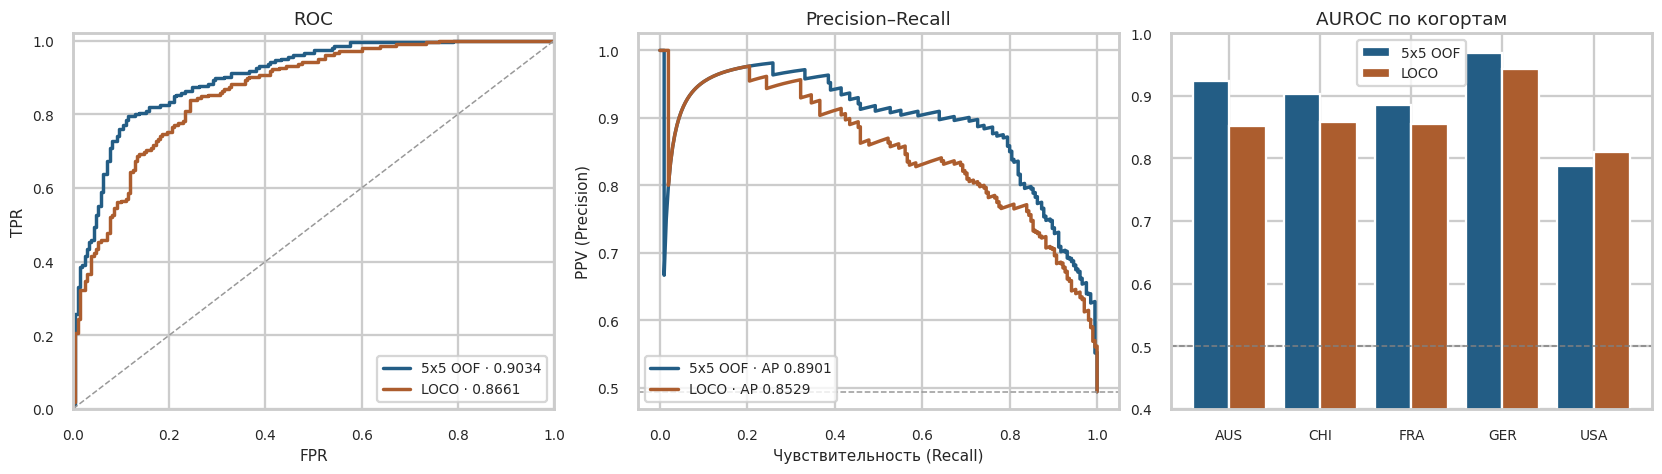

Диапазон предсказаний: OOF [0.018 0.455 0.995] | LOCO [0.024 0.451 0.996]


In [9]:
loco_df = pd.DataFrame(loco_records).set_index('Когорта')
display(loco_df.round(4))

summary = pd.DataFrame([
    {'Схема': '5x5 OOF (усреднено)', 'AUROC pooled': roc_auc_score(y, oof_mean),
     'AUROC средний по когортам': per_cohort_auc(y, oof_mean, cohorts),
     'AP': average_precision_score(y, oof_mean), 'Brier': brier_score_loss(y, oof_mean)},
    {'Схема': 'LOCO (новая когорта)', 'AUROC pooled': roc_auc_score(y, oof_loco),
     'AUROC средний по когортам': per_cohort_auc(y, oof_loco, cohorts),
     'AP': average_precision_score(y, oof_loco), 'Brier': brier_score_loss(y, oof_loco)},
]).set_index('Схема')
display(summary.round(4))
print(f'repeat_mean {np.mean(rep_aucs):.4f} ± {np.std(rep_aucs):.4f} | разброс AUROC по когортам (LOCO) '
      f'{loco_df["AUROC"].min():.4f} … {loco_df["AUROC"].max():.4f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout='constrained')
for name, p, color in [('5x5 OOF', oof_mean, '#235D85'), ('LOCO', oof_loco, '#AC5D2E')]:
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, color=color, label=f'{name} · {roc_auc_score(y, p):.4f}')
    prec, rec, _ = precision_recall_curve(y, p)
    axes[1].plot(rec, prec, color=color, label=f'{name} · AP {average_precision_score(y, p):.4f}')
axes[0].plot([0, 1], [0, 1], '--', color='.6', lw=1)
axes[0].set(title='ROC', xlabel='FPR', ylabel='TPR', xlim=(0, 1), ylim=(0, 1.02)); axes[0].legend(loc='lower right')
axes[1].axhline(y.mean(), color='.6', ls='--', lw=1)
axes[1].set(title='Precision–Recall', xlabel='Чувствительность (Recall)', ylabel='PPV (Precision)')
axes[1].legend(loc='lower left')

pos = np.arange(len(cohort_names))
axes[2].bar(pos - .2, [roc_auc_score(y[cohorts == c], oof_mean[cohorts == c]) for c in cohort_names],
            width=.4, label='5x5 OOF', color='#235D85')
axes[2].bar(pos + .2, loco_df.loc[cohort_names, 'AUROC'], width=.4, label='LOCO', color='#AC5D2E')
axes[2].axhline(.5, color='.5', ls='--', lw=1)
axes[2].set_xticks(pos, cohort_names); axes[2].set(title='AUROC по когортам', ylim=(.4, 1)); axes[2].legend()
plt.show()

pd.DataFrame(fold_records).to_csv('cv_fold_metrics.csv', index=False)
pd.DataFrame({'sample_id': train['sample_id'], 'label': y, 'cohort': cohorts,
              'oof_5x5': oof_mean, 'oof_loco': oof_loco}).to_csv('oof_predictions.csv', index=False)
print('Диапазон предсказаний: OOF', np.round(np.quantile(oof_mean, [0, .5, 1]), 3),
      '| LOCO', np.round(np.quantile(oof_loco, [0, .5, 1]), 3))

## Блок 4. Пороги и матрица ошибок (клиническая часть)

Обозначения (положительный класс = **КРР**):

|  | Прогноз: контроль | Прогноз: КРР |
| - | - | - |
| **Истина: контроль** | TN | **FP** — ложная тревога, лишняя колоноскопия |
| **Истина: КРР** | **FN** — пропущенный рак | TP |

- **Чувствительность (Se, recall)** = TP/(TP+FN) — какую долю раков находим.
- **Специфичность (Sp)** = TN/(TN+FP) — какую долю здоровых не тревожим.
- **PPV** = TP/(TP+FP), **NPV** = TN/(TN+FN) — зависят от распространённости.
- **F2**пропуски сильнее ложных тревог; **Youden J** = Se+Sp−1 assumes равную цену ошибок.
- **Цена ошибки**: `COST_FN * FN + COST_FP * FP`, здесь FN в 10 раз дороже FP.

Порядок честный: **порог подбираем на 5×5 OOF → применяем без изменений к LOCO** (другие когорты). Метрики, посчитанные на тех же данных, где выбирался порог, оптимистичны — это отмечено ниже.

,thr,TP,FP,FN,TN,sens,spec,ppv,npv,acc,ba,f1,f2,mcc,youden,lr_plus,lr_minus,ppr,cost,net_benefit
Схема,,,,,,,,,,,,,,,,,,,,
5x5 OOF,0.5,163,27,42,183,0.7951,0.8714,0.8579,0.8133,0.8337,0.8333,0.8253,0.8069,0.6689,0.6666,6.1843,0.2351,0.4578,447.0,0.3277
LOCO,0.5,148,36,57,174,0.7220,0.8286,0.8043,0.7532,0.7759,0.7753,0.7609,0.7371,0.5540,0.5505,4.2114,0.3356,0.4434,606.0,0.2699


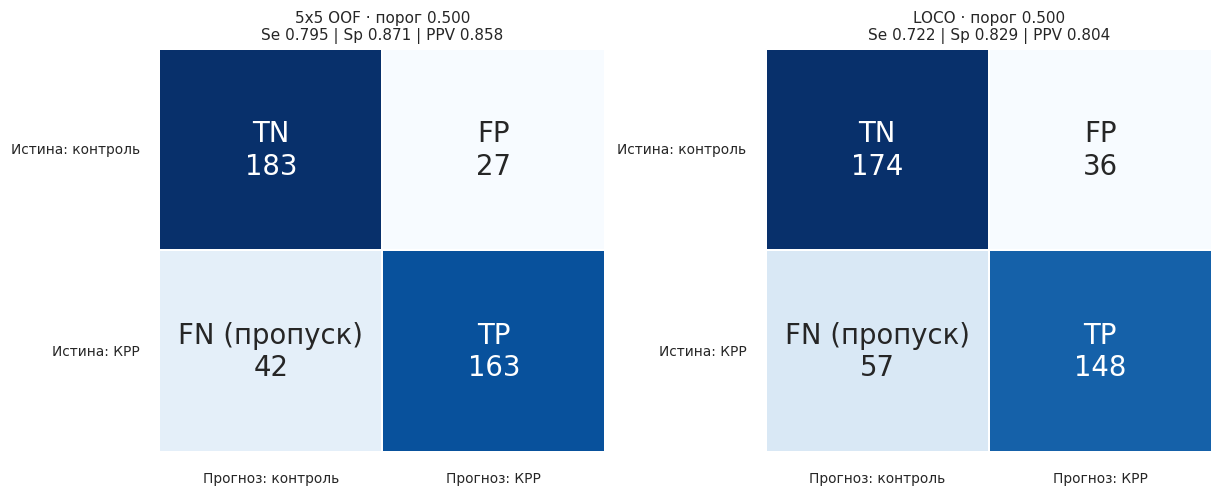

Порог 0.5 при сильно регуляризованной L2 — не нейтральная точка: вероятности сжаты к базовой доле КРР.
Базовая доля КРР = 0.494; медиана OOF = 0.455, медиана LOCO = 0.451.


In [10]:
def confusion_stats(y_true, p, thr):
    y_true = np.asarray(y_true).astype(int)
    pos_pred = np.asarray(p) >= thr
    tn, fp, fn, tp = confusion_matrix(y_true, pos_pred, labels=[0, 1]).ravel()
    n = len(y_true)
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    ppv = tp / (tp + fp) if (tp + fp) else np.nan
    npv = tn / (tn + fn) if (tn + fn) else np.nan
    denom = np.sqrt(float((tp + fp)) * (tp + fn) * (tn + fp) * (tn + fn))
    return {
        'thr': float(thr), 'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
        'sens': sens, 'spec': spec, 'ppv': ppv, 'npv': npv,
        'acc': (tp + tn) / n, 'ba': (sens + spec) / 2,
        'f1': 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan,
        'f2': 5 * tp / (5 * tp + 4 * fn + fp) if (5 * tp + 4 * fn + fp) else np.nan,
        'mcc': (tp * tn - fp * fn) / denom if denom > 0 else np.nan,
        'youden': sens + spec - 1,
        'lr_plus': sens / (1 - spec) if spec < 1 else np.inf,
        'lr_minus': (1 - sens) / spec if spec > 0 else np.inf,
        'ppr': (tp + fp) / n,
        'cost': COST_FN * fn + COST_FP * fp,
        'net_benefit': tp / n - (fp / n) * thr / (1 - thr),
    }


def plot_cm(ax, y_true, p, thr, title):
    s = confusion_stats(y_true, p, thr)
    cm = np.array([[s['TN'], s['FP']], [s['FN'], s['TP']]])
    annot = np.array([[f'TN\n{s["TN"]}', f'FP\n{s["FP"]}'], [f'FN (пропуск)\n{s["FN"]}', f'TP\n{s["TP"]}']])
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, linewidths=1, linecolor='w', ax=ax,
                xticklabels=['Прогноз: контроль', 'Прогноз: КРР'],
                yticklabels=['Истина: контроль', 'Истина: КРР'])
    ax.set_title(f'{title} · порог {thr:.3f}\nSe {s["sens"]:.3f} | Sp {s["spec"]:.3f} | PPV {s["ppv"]:.3f}',
                 fontsize=10)
    ax.tick_params(axis='y', rotation=0)


base_rows = []
for name, p in [('5x5 OOF', oof_mean), ('LOCO', oof_loco)]:
    base_rows.append({'Схема': name, **confusion_stats(y, p, 0.5)})
display(pd.DataFrame(base_rows).set_index('Схема').round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout='constrained')
plot_cm(axes[0], y, oof_mean, 0.5, '5x5 OOF')
plot_cm(axes[1], y, oof_loco, 0.5, 'LOCO')
plt.show()
print('Порог 0.5 при сильно регуляризованной L2 — не нейтральная точка: вероятности сжаты к базовой доле КРР.')
print(f'Базовая доля КРР = {y.mean():.3f}; медиана OOF = {np.median(oof_mean):.3f}, медиана LOCO = {np.median(oof_loco):.3f}.')

In [11]:
THRESHOLDS = np.round(np.arange(0.02, 0.981, 0.005), 3)
sweep = pd.DataFrame([confusion_stats(y, oof_mean, t) for t in THRESHOLDS])
sweep_loco = pd.DataFrame([confusion_stats(y, oof_loco, t) for t in THRESHOLDS])
sweep.to_csv('threshold_sweep_oof.csv', index=False)


def thr_for_sens(sw, target):
    ok = sw[sw['sens'] >= target]
    if ok.empty:
        return float(sw['thr'].min())
    best = ok['spec'].max()
    return float(ok.loc[ok['spec'] == best, 'thr'].max())


def thr_for_spec(sw, target):
    ok = sw[sw['spec'] >= target]
    if ok.empty:
        return float(sw['thr'].max())
    best = ok['sens'].max()
    return float(ok.loc[ok['sens'] == best, 'thr'].max())


RULES = {
    'Базовый 0.50': 0.50,
    'Youden J (равная цена)': float(sweep.loc[sweep['youden'].idxmax(), 'thr']),
    'Максимум F1': float(sweep.loc[sweep['f1'].idxmax(), 'thr']),
    'Максимум F2 (вес FN)': float(sweep.loc[sweep['f2'].idxmax(), 'thr']),
    'Максимум MCC': float(sweep.loc[sweep['mcc'].idxmax(), 'thr']),
    f'Se >= 0.90 -> max Sp': thr_for_sens(sweep, 0.90),
    f'Se >= {TARGET_SENS} -> max Sp (скрининг)': thr_for_sens(sweep, TARGET_SENS),
    f'Sp >= {TARGET_SPEC} -> max Se (подтверждение)': thr_for_spec(sweep, TARGET_SPEC),
    f'Минимум цены FN:FP = {COST_FN:.0f}:{COST_FP:.0f}': float(sweep.loc[sweep['cost'].idxmin(), 'thr']),
    'Доля положительных = доле КРР': float(sweep.loc[(sweep['ppr'] - y.mean()).abs().idxmin(), 'thr']),
}

rule_rows = []
for rule, thr in RULES.items():
    s_oof = confusion_stats(y, oof_mean, thr)
    s_loco = confusion_stats(y, oof_loco, thr)
    rule_rows.append({'Правило': rule, 'Порог': thr,
                      'TP': s_oof['TP'], 'FP': s_oof['FP'], 'FN': s_oof['FN'], 'TN': s_oof['TN'],
                      'Se OOF': s_oof['sens'], 'Sp OOF': s_oof['spec'], 'PPV OOF': s_oof['ppv'],
                      'NPV OOF': s_oof['npv'], 'F2 OOF': s_oof['f2'],
                      'Se LOCO': s_loco['sens'], 'Sp LOCO': s_loco['spec'], 'FN LOCO': s_loco['FN']})
rules_df = pd.DataFrame(rule_rows).set_index('Правило')
rules_df.to_csv('threshold_rules.csv')
display(rules_df.round(3))
print('Столбцы LOCO — тот же порог без подстройки: это честная проверка переноса порога на новую когорту.')

,Порог,TP,FP,FN,TN,Se OOF,Sp OOF,PPV OOF,NPV OOF,F2 OOF,Se LOCO,Sp LOCO,FN LOCO
Правило,,,,,,,,,,,,,
Базовый 0.50,0.500,163,27,42,183,0.795,0.871,0.858,0.813,0.807,0.722,0.829,57
Youden J (равная цена),0.505,163,25,42,185,0.795,0.881,0.867,0.815,0.809,0.707,0.833,60
Максимум F1,0.505,163,25,42,185,0.795,0.881,0.867,0.815,0.809,0.707,0.833,60
Максимум F2 (вес FN),0.215,204,123,1,87,0.995,0.414,0.624,0.989,0.889,0.985,0.333,3
Максимум MCC,0.505,163,25,42,185,0.795,0.881,0.867,0.815,0.809,0.707,0.833,60
Se >= 0.90 -> max Sp,0.375,185,67,20,143,0.902,0.681,0.734,0.877,0.863,0.873,0.676,26
Se >= 0.95 -> max Sp (скрининг),0.280,195,94,10,116,0.951,0.552,0.675,0.921,0.879,0.951,0.486,10
Sp >= 0.9 -> max Se (подтверждение),0.520,156,21,49,189,0.761,0.900,0.881,0.794,0.782,0.688,0.867,64
Минимум цены FN:FP = 10:1,0.215,204,123,1,87,0.995,0.414,0.624,0.989,0.889,0.985,0.333,3


Столбцы LOCO — тот же порог без подстройки: это честная проверка переноса порога на новую когорту.


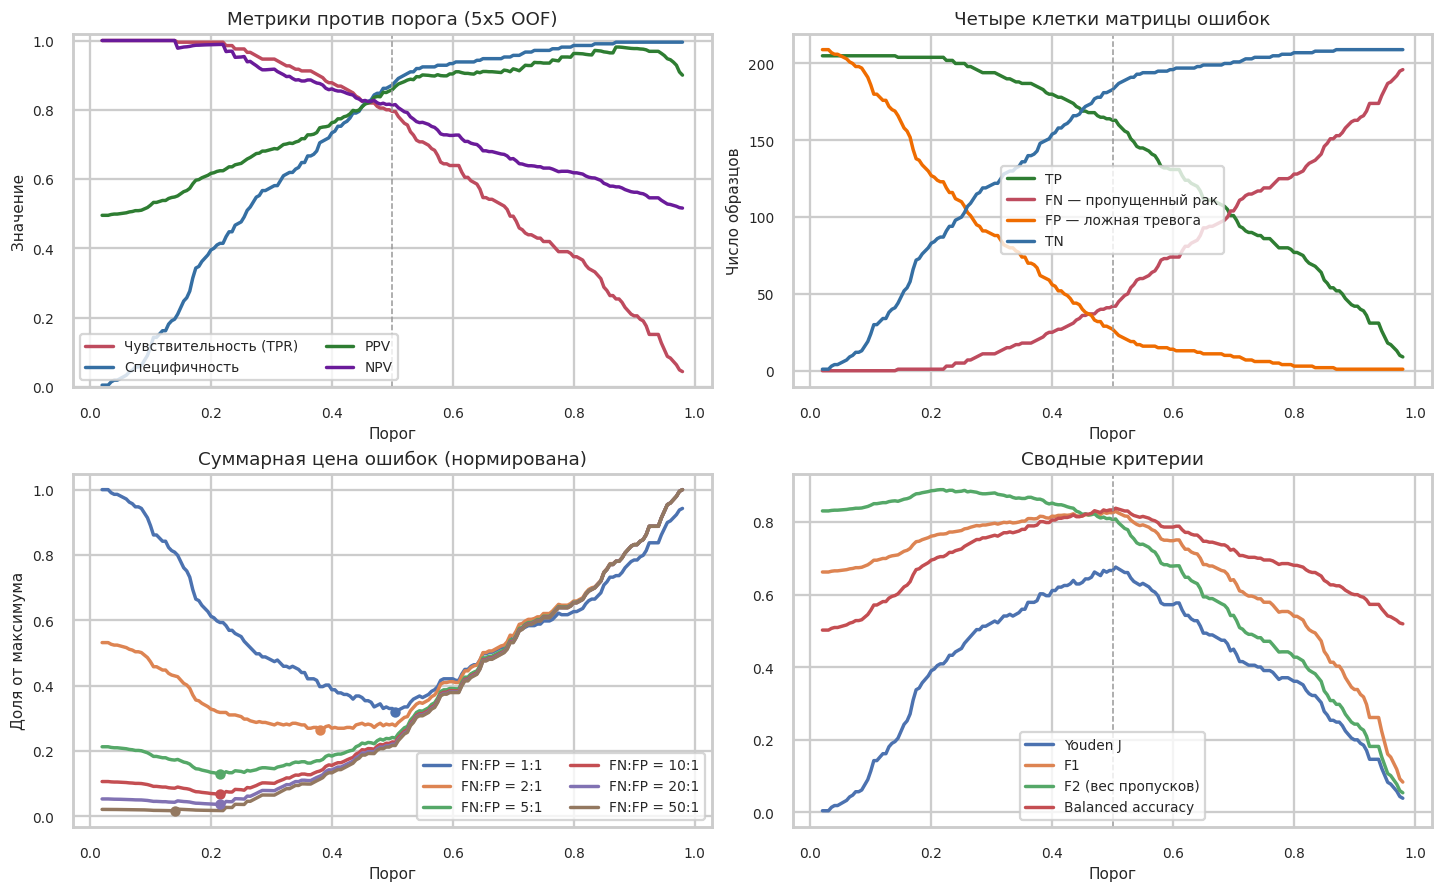

Как цена ошибки двигает порог:


,Порог,TP,FN,FP,Se OOF,Sp OOF,Se LOCO,Sp LOCO
FN:FP,,,,,,,,
1:1,0.505,163,42,25,0.795,0.881,0.707,0.833
2:1,0.380,184,21,62,0.898,0.705,0.868,0.686
5:1,0.215,204,1,123,0.995,0.414,0.985,0.333
10:1,0.215,204,1,123,0.995,0.414,0.985,0.333
20:1,0.215,204,1,123,0.995,0.414,0.985,0.333
50:1,0.140,205,0,169,1.000,0.195,1.000,0.176
100:1,0.140,205,0,169,1.000,0.195,1.000,0.176


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')

ax = axes[0, 0]
for col, lab, c in [('sens', 'Чувствительность (TPR)', '#BE4B5E'), ('spec', 'Специфичность', '#356FA3'),
                    ('ppv', 'PPV', '#2E7D32'), ('npv', 'NPV', '#6A1B9A')]:
    ax.plot(sweep['thr'], sweep[col], label=lab, color=c)
ax.axvline(0.5, color='.6', ls='--', lw=1)
ax.set(title='Метрики против порога (5x5 OOF)', xlabel='Порог', ylabel='Значение', ylim=(0, 1.02))
ax.legend(loc='lower left', ncol=2)

ax = axes[0, 1]
for col, lab, c in [('TP', 'TP', '#2E7D32'), ('FN', 'FN — пропущенный рак', '#BE4B5E'),
                    ('FP', 'FP — ложная тревога', '#EF6C00'), ('TN', 'TN', '#356FA3')]:
    ax.plot(sweep['thr'], sweep[col], label=lab, color=c)
ax.axvline(0.5, color='.6', ls='--', lw=1)
ax.set(title='Четыре клетки матрицы ошибок', xlabel='Порог', ylabel='Число образцов')
ax.legend()

ax = axes[1, 0]
for ratio in [1, 2, 5, 10, 20, 50]:
    cost = ratio * sweep['FN'] + sweep['FP']
    ax.plot(sweep['thr'], cost / cost.max(), label=f'FN:FP = {ratio}:1')
    t_opt = float(sweep.loc[cost.idxmin(), 'thr'])
    ax.scatter([t_opt], [cost.min() / cost.max()], s=28, zorder=5)
ax.set(title='Суммарная цена ошибок (нормирована)', xlabel='Порог', ylabel='Доля от максимума')
ax.legend(ncol=2)

ax = axes[1, 1]
ax.plot(sweep['thr'], sweep['youden'], label='Youden J')
ax.plot(sweep['thr'], sweep['f1'], label='F1')
ax.plot(sweep['thr'], sweep['f2'], label='F2 (вес пропусков)')
ax.plot(sweep['thr'], sweep['ba'], label='Balanced accuracy')
ax.axvline(0.5, color='.6', ls='--', lw=1)
ax.set(title='Сводные критерии', xlabel='Порог'); ax.legend()
plt.show()

print('Как цена ошибки двигает порог:')
rows = []
for ratio in [1, 2, 5, 10, 20, 50, 100]:
    cost = ratio * sweep['FN'] + sweep['FP']
    s = confusion_stats(y, oof_mean, float(sweep.loc[cost.idxmin(), 'thr']))
    sl = confusion_stats(y, oof_loco, s['thr'])
    rows.append({'FN:FP': f'{ratio}:1', 'Порог': s['thr'], 'TP': s['TP'], 'FN': s['FN'], 'FP': s['FP'],
                 'Se OOF': s['sens'], 'Sp OOF': s['spec'], 'Se LOCO': sl['sens'], 'Sp LOCO': sl['spec']})
display(pd.DataFrame(rows).set_index('FN:FP').round(3))

In [13]:
# Целевые уровни чувствительности и специфичности — прямой размен TP <-> FN
rows = []
for target in [0.80, 0.85, 0.90, 0.95, 0.98, 1.00]:
    t = thr_for_sens(sweep, target)
    s, sl = confusion_stats(y, oof_mean, t), confusion_stats(y, oof_loco, t)
    rows.append({'Требование': f'Se >= {target:.2f}', 'Порог': t, 'Se OOF': s['sens'], 'Sp OOF': s['spec'],
                 'FN OOF': s['FN'], 'FP OOF': s['FP'], 'FP на 1000 здоровых': round((1 - s['spec']) * 1000),
                 'Se LOCO': sl['sens'], 'Sp LOCO': sl['spec'], 'FN LOCO': sl['FN']})
display(pd.DataFrame(rows).set_index('Требование').round(3))

rows = []
for target in [0.80, 0.85, 0.90, 0.95, 0.98]:
    t = thr_for_spec(sweep, target)
    s, sl = confusion_stats(y, oof_mean, t), confusion_stats(y, oof_loco, t)
    rows.append({'Требование': f'Sp >= {target:.2f}', 'Порог': t, 'Se OOF': s['sens'], 'Sp OOF': s['spec'],
                 'FN OOF': s['FN'], 'PPV OOF': s['ppv'], 'FN на 1000 больных': round((1 - s['sens']) * 1000),
                 'Se LOCO': sl['sens'], 'Sp LOCO': sl['spec']})
display(pd.DataFrame(rows).set_index('Требование').round(3))
print('Каждый шаг порога вверх — это спасённые от лишней колоноскопии здоровые и дополнительно пропущенные раки.')

,Порог,Se OOF,Sp OOF,FN OOF,FP OOF,FP на 1000 здоровых,Se LOCO,Sp LOCO,FN LOCO
Требование,,,,,,,,,
Se >= 0.80,0.495,0.800,0.867,41,28,133,0.727,0.829,56
Se >= 0.85,0.430,0.854,0.776,30,47,224,0.810,0.762,39
Se >= 0.90,0.375,0.902,0.681,20,67,319,0.873,0.676,26
Se >= 0.95,0.280,0.951,0.552,10,94,448,0.951,0.486,10
Se >= 0.98,0.235,0.985,0.448,3,116,552,0.980,0.390,4
Se >= 1.00,0.140,1.000,0.195,0,169,805,1.000,0.176,0


,Порог,Se OOF,Sp OOF,FN OOF,PPV OOF,FN на 1000 больных,Se LOCO,Sp LOCO
Требование,,,,,,,,
Sp >= 0.80,0.455,0.824,0.819,36,0.816,176,0.771,0.786
Sp >= 0.85,0.485,0.805,0.862,40,0.851,195,0.741,0.819
Sp >= 0.90,0.520,0.761,0.900,49,0.881,239,0.688,0.867
Sp >= 0.95,0.685,0.522,0.952,98,0.915,478,0.459,0.929
Sp >= 0.98,0.790,0.390,0.981,125,0.952,610,0.356,0.971


Каждый шаг порога вверх — это спасённые от лишней колоноскопии здоровые и дополнительно пропущенные раки.


Рабочий порог (Se >= 0.95): 0.280 | подтверждающий (Sp >= 0.9): 0.520


,thr,TP,FP,FN,TN,sens,spec,ppv,npv,acc,ba,f1,f2,mcc,youden,lr_plus,lr_minus,ppr,cost,net_benefit
Схема,,,,,,,,,,,,,,,,,,,,
5x5 OOF (порог подобран здесь),0.28,195,94,10,116,0.9512,0.5524,0.6747,0.9206,0.7494,0.7518,0.7895,0.8792,0.5476,0.5036,2.1251,0.0883,0.6964,194.0,0.3818
LOCO (порог перенесён),0.28,195,108,10,102,0.9512,0.4857,0.6436,0.9107,0.7157,0.7185,0.7677,0.8682,0.4921,0.4369,1.8496,0.1004,0.7301,208.0,0.3687


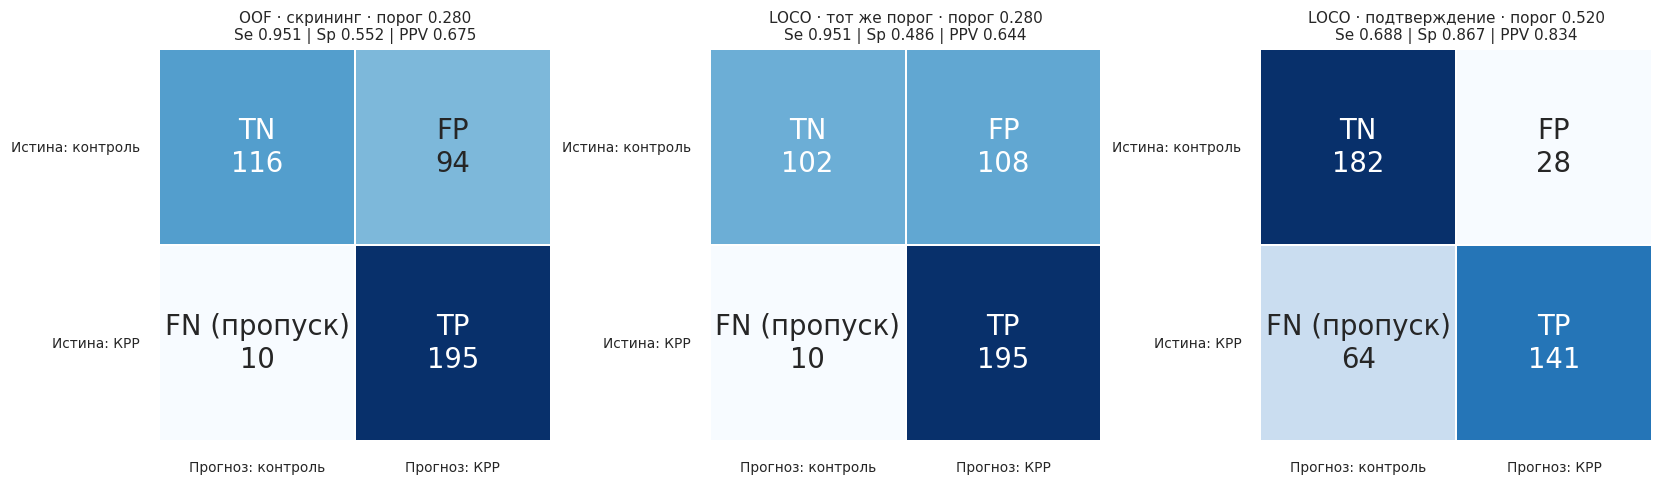

,Оценка,CI 2.5%,CI 97.5%
Метрика,,,
sens,0.9512,0.9220,0.9805
spec,0.4857,0.4190,0.5571
ppv,0.6436,0.6139,0.6782
npv,0.9107,0.8596,0.9626
ba,0.7185,0.6807,0.7567
f2,0.8682,0.8423,0.8938


 Bootstrap стратифицирован по диагнозу; интервалы для LOCO при ФИКСИРОВАННОМ пороге.
Неопределённость самого выбора порога оценена ниже по повторам и когортам.


In [14]:
# Рабочие пороги: фиксируются на OOF
THR_MAIN = thr_for_sens(sweep, TARGET_SENS)          # скрининговый (rule-out)
THR_RULEIN = thr_for_spec(sweep, TARGET_SPEC)        # подтверждающий (rule-in)
THR_YOUDEN = float(sweep.loc[sweep['youden'].idxmax(), 'thr'])
print(f'Рабочий порог (Se >= {TARGET_SENS}): {THR_MAIN:.3f} | подтверждающий (Sp >= {TARGET_SPEC}): {THR_RULEIN:.3f}')

s_main_oof = confusion_stats(y, oof_mean, THR_MAIN)
s_main_loco = confusion_stats(y, oof_loco, THR_MAIN)
display(pd.DataFrame([{'Схема': '5x5 OOF (порог подобран здесь)', **s_main_oof},
                      {'Схема': 'LOCO (порог перенесён)', **s_main_loco}]).set_index('Схема').round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), layout='constrained')
plot_cm(axes[0], y, oof_mean, THR_MAIN, 'OOF · скрининг')
plot_cm(axes[1], y, oof_loco, THR_MAIN, 'LOCO · тот же порог')
plot_cm(axes[2], y, oof_loco, THR_RULEIN, 'LOCO · подтверждение')
plt.show()


def bootstrap_ci(y_true, p, thr, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true).astype(int)
    i1, i0 = np.flatnonzero(y_true == 1), np.flatnonzero(y_true == 0)
    keys = ['sens', 'spec', 'ppv', 'npv', 'ba', 'f2']
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(i1, len(i1), True), rng.choice(i0, len(i0), True)])
        s = confusion_stats(y_true[idx], np.asarray(p)[idx], thr)
        vals.append([s[k] for k in keys])
    arr = np.asarray(vals, dtype=float)
    point = confusion_stats(y_true, p, thr)
    return pd.DataFrame({'Метрика': keys,
                         'Оценка': [point[k] for k in keys],
                         'CI 2.5%': np.nanpercentile(arr, 2.5, axis=0),
                         'CI 97.5%': np.nanpercentile(arr, 97.5, axis=0)}).set_index('Метрика')


with lim():
    display(bootstrap_ci(y, oof_loco, THR_MAIN).round(4))
print(' Bootstrap стратифицирован по диагнозу; интервалы для LOCO при ФИКСИРОВАННОМ пороге.')
print('Неопределённость самого выбора порога оценена ниже по повторам и когортам.')

In [15]:
def sweep_counts(y_true, p, thrs):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p)
    ps, pc = np.sort(p[y_true == 1]), np.sort(p[y_true == 0])
    k1 = np.searchsorted(ps, thrs, side='left')
    k0 = np.searchsorted(pc, thrs, side='left')
    fn, tp = k1, len(ps) - k1
    tn, fp = k0, len(pc) - k0
    return tp, fp, fn, tn


# Устойчивость порога: по 5 повторам OOF, по 5 когортам LOCO и по bootstrap
grid = np.round(np.arange(0.02, 0.981, 0.01), 3)
stab = []
for r, p in enumerate(rep_oofs, 1):
    sw = pd.DataFrame([confusion_stats(y, p, t) for t in grid])
    stab.append({'Источник': f'OOF повтор {r}', 'Порог Se95': thr_for_sens(sw, TARGET_SENS),
                 'Порог Youden': float(sw.loc[sw['youden'].idxmax(), 'thr'])})
for c in cohort_names:
    m = cohorts == c
    sw = pd.DataFrame([confusion_stats(y[m], oof_loco[m], t) for t in grid])
    stab.append({'Источник': f'LOCO {c}', 'Порог Se95': thr_for_sens(sw, TARGET_SENS),
                 'Порог Youden': float(sw.loc[sw['youden'].idxmax(), 'thr'])})
stab_df = pd.DataFrame(stab).set_index('Источник')
display(stab_df.round(3))

rng = np.random.default_rng(SEED)
i1, i0 = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
boot_thr = []
for _ in range(300):
    idx = np.concatenate([rng.choice(i1, len(i1), True), rng.choice(i0, len(i0), True)])
    tp, fp, fn, tn = sweep_counts(y[idx], oof_mean[idx], grid)
    sens = tp / np.maximum(tp + fn, 1)
    ok = np.flatnonzero(sens >= TARGET_SENS)
    boot_thr.append(grid[ok[-1]] if len(ok) else grid[0])
boot_thr = np.asarray(boot_thr)
print(f'Bootstrap порога Se>=95%: медиана {np.median(boot_thr):.3f}, '
      f'95% интервал [{np.percentile(boot_thr, 2.5):.3f}; {np.percentile(boot_thr, 97.5):.3f}]')
print('Разброс по когортам — это межкогортный сдвиг; единый порог для всех стран не гарантирован.')

,Порог Se95,Порог Youden
Источник,,
OOF повтор 1,0.26,0.46
OOF повтор 2,0.30,0.54
OOF повтор 3,0.28,0.45
OOF повтор 4,0.27,0.48
OOF повтор 5,0.29,0.48
LOCO AUS,0.28,0.41
LOCO CHI,0.36,0.52
LOCO FRA,0.25,0.49
LOCO GER,0.29,0.38


Bootstrap порога Se>=95%: медиана 0.280, 95% интервал [0.250; 0.350]
Разброс по когортам — это межкогортный сдвиг; единый порог для всех стран не гарантирован.


Зоны: p < 0.280 — низкий риск | 0.280 <= p < 0.520 — серая зона | p >= 0.520 — высокий риск


,Схема,Зона,n,доля,КРР,доля КРР в зоне,пропущено КРР (FN)
0,5x5 OOF,Низкий риск,126,0.3036,10,0.0794,10
1,5x5 OOF,Серая зона,112,0.2699,39,0.3482,0
2,5x5 OOF,Высокий риск,177,0.4265,156,0.8814,0
3,LOCO,Низкий риск,112,0.2699,10,0.0893,10
4,LOCO,Серая зона,134,0.3229,54,0.4030,0
5,LOCO,Высокий риск,169,0.4072,141,0.8343,0


LOCO: в зону низкого риска попали 10 из 205 КРР (4.9%). Серая зона: 32.3% выборки.


,n,доля КРР,"Низкий риск, n","Серая зона, n","Высокий риск, n",КРР в низком риске,КРР в высоком риске
Когорта,,,,,,,
AUS,79,0.392,26,26,27,1,20
CHI,99,0.586,15,35,49,2,43
FRA,80,0.462,25,18,37,3,28
GER,87,0.494,34,24,29,2,29
USA,70,0.514,12,31,27,2,21


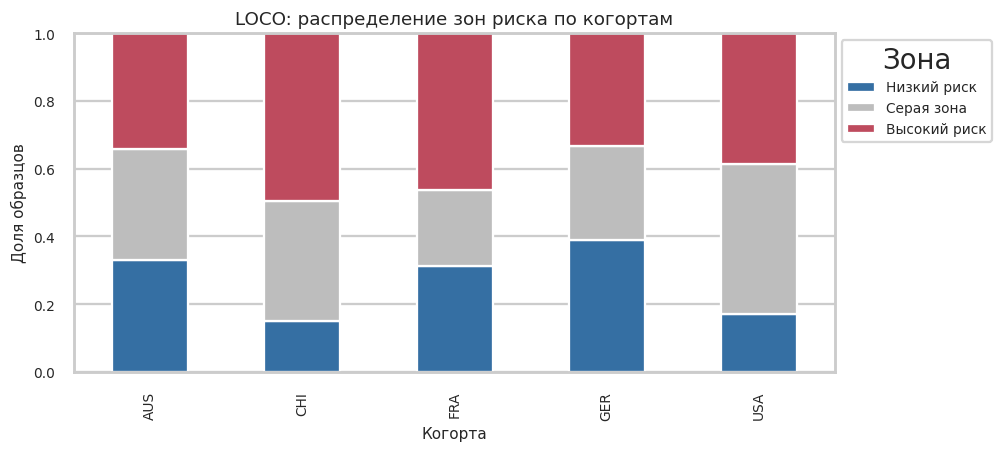

In [16]:
# Трёхзонная схема: исключить / серая зона / направить. Серая зона = повторный или другой тест.
T_LOW, T_HIGH = min(THR_MAIN, THR_RULEIN), max(THR_MAIN, THR_RULEIN)
if THR_MAIN > THR_RULEIN:
    print('Внимание: скрининговый порог выше подтверждающего — серая зона вырождается, порядок зонswap не нужен.')
print(f'Зоны: p < {T_LOW:.3f} — низкий риск | {T_LOW:.3f} <= p < {T_HIGH:.3f} — серая зона | p >= {T_HIGH:.3f} — высокий риск')


def zones(p, t_low=T_LOW, t_high=T_HIGH):
    return np.where(p < t_low, 'Низкий риск', np.where(p >= t_high, 'Высокий риск', 'Серая зона'))


ZONE_ORDER = ['Низкий риск', 'Серая зона', 'Высокий риск']
rows = []
for scheme, p in [('5x5 OOF', oof_mean), ('LOCO', oof_loco)]:
    z = zones(p)
    for name in ZONE_ORDER:
        m = z == name
        n, k = int(m.sum()), int(y[m].sum())
        rows.append({'Схема': scheme, 'Зона': name, 'n': n, 'доля': n / len(y), 'КРР': k,
                     'доля КРР в зоне': k / n if n else np.nan,
                     'пропущено КРР (FN)': k if name == 'Низкий риск' else 0})
zone_df = pd.DataFrame(rows)
display(zone_df.round(4))

missed = int(zone_df[(zone_df['Схема'] == 'LOCO') & (zone_df['Зона'] == 'Низкий риск')]['КРР'].iloc[0])
total_crc = int(y.sum())
print(f'LOCO: в зону низкого риска попали {missed} из {total_crc} КРР ({missed/total_crc:.1%}). '
      f'Серая зона: {zone_df[(zone_df["Схема"]=="LOCO") & (zone_df["Зона"]=="Серая зона")]["доля"].iloc[0]:.1%} выборки.')

rows = []
for c in cohort_names:
    m = cohorts == c
    z = zones(oof_loco[m])
    rows.append({'Когорта': c, 'n': int(m.sum()), 'доля КРР': y[m].mean(),
                 **{f'{name}, n': int((z == name).sum()) for name in ZONE_ORDER},
                 'КРР в низком риске': int(y[m][z == 'Низкий риск'].sum()),
                 'КРР в высоком риске': int(y[m][z == 'Высокий риск'].sum())})
display(pd.DataFrame(rows).set_index('Когорта').round(3))

fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
zz = zones(oof_loco)
counts = pd.crosstab(pd.Series(cohorts, name='Когорта'), pd.Series(zz, name='Зона'))[ZONE_ORDER]
counts.div(counts.sum(axis=1), axis=0).plot(kind='bar', stacked=True, ax=ax,
                                            color=['#356FA3', '#BDBDBD', '#BE4B5E'])
ax.set(title='LOCO: распределение зон риска по когортам', ylabel='Доля образцов', ylim=(0, 1))
ax.legend(title='Зона', bbox_to_anchor=(1, 1), loc='upper left')
plt.show()

,PPV,NPV,FN на 100 000,FP на 100 000
Распространённость КРР,,,,
0.5%,0.0092,0.9995,24,51171
1.0%,0.0183,0.9990,49,50914
3.0%,0.0541,0.9969,146,49886
5.0%,0.0887,0.9947,244,48857
10.0%,0.1705,0.9890,488,46286
20.0%,0.3162,0.9755,976,41143
49.4%,0.6436,0.9107,2410,26024


Расчёт при фиксированных Se = 0.951 и Sp = 0.486 (LOCO, порог 0.280).
В популяционном скрининге с низкой распространённостью PPV падает — нужен подтверждающий тест.


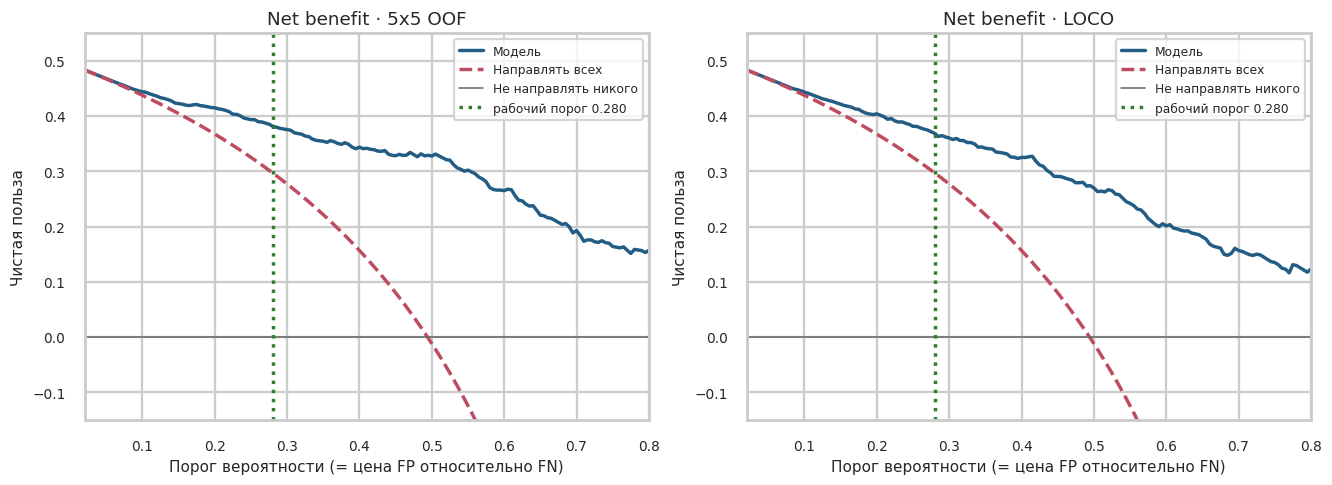

OOF: net benefit модели 0.3818 против "направлять всех" 0.2972
LOCO: net benefit модели 0.3687 против "направлять всех" 0.2972


In [17]:
# PPV/NPV зависят от распространённости: переносим Se/Sp на скрининговую популяцию
sens, spec = s_main_loco['sens'], s_main_loco['spec']
rows = []
for prev in [0.005, 0.01, 0.03, 0.05, 0.10, 0.20, float(y.mean())]:
    ppv = sens * prev / (sens * prev + (1 - spec) * (1 - prev))
    npv = spec * (1 - prev) / (spec * (1 - prev) + (1 - sens) * prev)
    rows.append({'Распространённость КРР': f'{prev:.1%}', 'PPV': ppv, 'NPV': npv,
                 'FN на 100 000': round((1 - sens) * prev * 100000),
                 'FP на 100 000': round((1 - spec) * (1 - prev) * 100000)})
display(pd.DataFrame(rows).set_index('Распространённость КРР').round(4))
print(f'Расчёт при фиксированных Se = {sens:.3f} и Sp = {spec:.3f} (LOCO, порог {THR_MAIN:.3f}).')
print('В популяционном скрининге с низкой распространённостью PPV падает — нужен подтверждающий тест.')

# Decision curve: чистая польза против "лечить всех" и "не лечить никого"
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
for ax, (name, sw) in zip(axes, [('5x5 OOF', sweep), ('LOCO', sweep_loco)]):
    t = sw['thr'].to_numpy()
    nb_all = y.mean() - (1 - y.mean()) * t / (1 - t)
    ax.plot(t, sw['net_benefit'], label='Модель', color='#235D85')
    ax.plot(t, nb_all, label='Направлять всех', color='#BE4B5E', ls='--')
    ax.axhline(0, color='.4', label='Не направлять никого', lw=1)
    ax.axvline(THR_MAIN, color='#2E7D32', ls=':', label=f'рабочий порог {THR_MAIN:.3f}')
    ax.set(title=f'Net benefit · {name}', xlabel='Порог вероятности (= цена FP относительно FN)',
           ylabel='Чистая польза', xlim=(0.02, 0.8), ylim=(-0.15, 0.55))
    ax.legend(fontsize=8)
plt.show()
for name, p in [('OOF', oof_mean), ('LOCO', oof_loco)]:
    s = confusion_stats(y, p, THR_MAIN)
    nb_all = y.mean() - (1 - y.mean()) * THR_MAIN / (1 - THR_MAIN)
    print(f'{name}: net benefit модели {s["net_benefit"]:.4f} против "направлять всех" {nb_all:.4f}')

,n,прогноз,факт,сдвиг
cohort,,,,
AUS,79,0.4328,0.3924,0.0404
CHI,99,0.5642,0.5859,-0.0216
FRA,80,0.5024,0.4625,0.0399
GER,87,0.4276,0.4943,-0.0666
USA,70,0.4964,0.5143,-0.0179


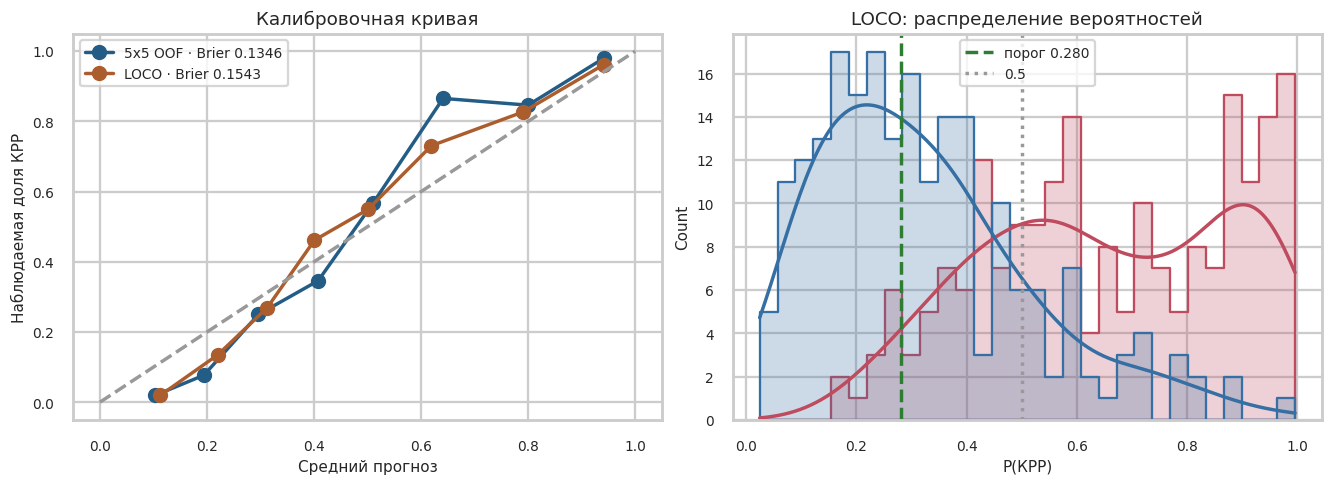

Сдвиг прогноз-факт по когортам показывает, где единый порог будет систематически ошибаться.


In [18]:
# Калибровка: порог имеет смысл только если вероятности осмысленны
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
for name, p, color in [('5x5 OOF', oof_mean, '#235D85'), ('LOCO', oof_loco, '#AC5D2E')]:
    frac_pos, mean_pred = calibration_curve(y, p, n_bins=8, strategy='quantile')
    axes[0].plot(mean_pred, frac_pos, 'o-', color=color, label=f'{name} · Brier {brier_score_loss(y, p):.4f}')
axes[0].plot([0, 1], [0, 1], '--', color='.6')
axes[0].set(title='Калибровочная кривая', xlabel='Средний прогноз', ylabel='Наблюдаемая доля КРР')
axes[0].legend()

cal = pd.DataFrame({'cohort': cohorts, 'y': y, 'p': oof_loco})
tab = cal.groupby('cohort').agg(n=('y', 'size'), прогноз=('p', 'mean'), факт=('y', 'mean'))
tab['сдвиг'] = tab['прогноз'] - tab['факт']
display(tab.round(4))

sns.histplot(x=oof_loco, hue=pd.Series(y).map(GROUP_NAMES), bins=30, kde=True,
             palette=CLASS_COLORS, ax=axes[1], element='step')
axes[1].axvline(THR_MAIN, color='#2E7D32', ls='--', label=f'порог {THR_MAIN:.3f}')
axes[1].axvline(0.5, color='.6', ls=':', label='0.5')
axes[1].set(title='LOCO: распределение вероятностей', xlabel='P(КРР)'); axes[1].legend()
plt.show()
print('Сдвиг прогноз-факт по когортам показывает, где единый порог будет систематически ошибаться.')

In [19]:
# Применение порогов к test (меток нет — только распределение зон)
test_out = pd.DataFrame({'sample_id': test['sample_id'], 'label': test_preds})
test_out['cohort'] = test['cohort'].values
test_out['zone'] = zones(test_preds)
test_out['pred_main'] = (test_preds >= THR_MAIN).astype(int)
test_out.to_csv('test_predictions_thresholds.csv', index=False)

sub = pd.DataFrame({'sample_id': test['sample_id'], 'label': test_preds})
sub.to_csv('sub_best_l2_bin.csv', index=False)

display(pd.crosstab(test_out['cohort'], test_out['zone'])[ZONE_ORDER])
print('Доли зон в test:', (test_out['zone'].value_counts(normalize=True).reindex(ZONE_ORDER)).round(3).to_dict())
print('Сабмит sub_best_l2_bin.csv содержит ВЕРОЯТНОСТИ (метрика ROC-AUC), не классы.')
print('Классы и зоны — в test_predictions_thresholds.csv, для клинической интерпретации.')
display(test_out.head())

zone,Низкий риск,Серая зона,Высокий риск
cohort,,,
AUS,8,9,13
CHI,6,5,18
FRA,11,5,18
GER,11,7,15
USA,5,16,13


Доли зон в test: {'Низкий риск': 0.256, 'Серая зона': 0.262, 'Высокий риск': 0.481}
Сабмит sub_best_l2_bin.csv содержит ВЕРОЯТНОСТИ (метрика ROC-AUC), не классы.
Классы и зоны — в test_predictions_thresholds.csv, для клинической интерпретации.


,sample_id,label,cohort,zone,pred_main
0,S0125,0.558541,USA,Высокий риск,1
1,S0242,0.420841,USA,Серая зона,1
2,S0053,0.362213,GER,Серая зона,1
3,S0173,0.298568,CHI,Серая зона,1
4,S0453,0.651213,CHI,Высокий риск,1


## Блок 5. Исследования

Всё ниже — **описательная статистика и интерпретация уже обученной модели**, на качество модели не влияет.
Ассоциации относительных долей композиционны: рост доли одного таксона механически снижает остальные. Причинность не утверждается.

,coef_full,частота отбора,согласие знака,средний coef
bin::Parvimonas micra [ref_mOTU_v2_1145],0.0615,1.0,1.0,0.0539
genus::Fusobacterium,0.0575,1.0,1.0,0.0537
bin::Gemella morbillorum [ref_mOTU_v2_4513],0.0567,1.0,1.0,0.0490
genus::Parvimonas,0.0565,1.0,1.0,0.0505
Parvimonas micra [ref_mOTU_v2_1145],0.0560,1.0,1.0,0.0502
Fusobacterium nucleatum s. animalis [ref_mOTU_v2_0776],0.0521,1.0,1.0,0.0460
Gemella morbillorum [ref_mOTU_v2_4513],0.0513,1.0,1.0,0.0456
bin::Fusobacterium nucleatum s. animalis [ref_mOTU_v2_0776],0.0479,1.0,1.0,0.0426
bin::Solobacterium moorei [ref_mOTU_v2_0531],0.0479,1.0,1.0,0.0418
bin::unknown Dialister [meta_mOTU_v2_5867],0.0475,1.0,1.0,0.0428


,coef_full,частота отбора,согласие знака,средний coef
bin::unknown Veillonellaceae [meta_mOTU_v2_6765],NaN,0.12,0.0,0.0078
unknown Prevotella [meta_mOTU_v2_6911],NaN,0.08,0.0,0.0182
bin::unknown Prevotella [meta_mOTU_v2_6911],NaN,0.08,0.0,0.0188
unknown Bacteroidales [meta_mOTU_v2_7089],NaN,0.12,0.0,0.0020
bin::unknown Bacteroidales [meta_mOTU_v2_7089],NaN,0.12,0.0,0.0097
Succinatimonas hippei [ref_mOTU_v2_4944],NaN,0.12,0.0,-0.0181
bin::Succinatimonas hippei [ref_mOTU_v2_4944],NaN,0.12,0.0,-0.0198
unknown Clostridiales [meta_mOTU_v2_7058],NaN,0.12,0.0,-0.0170
unknown Prevotella [meta_mOTU_v2_6289],NaN,0.04,0.0,0.0080
bin::unknown Clostridiales [meta_mOTU_v2_7058],NaN,0.12,0.0,-0.0110


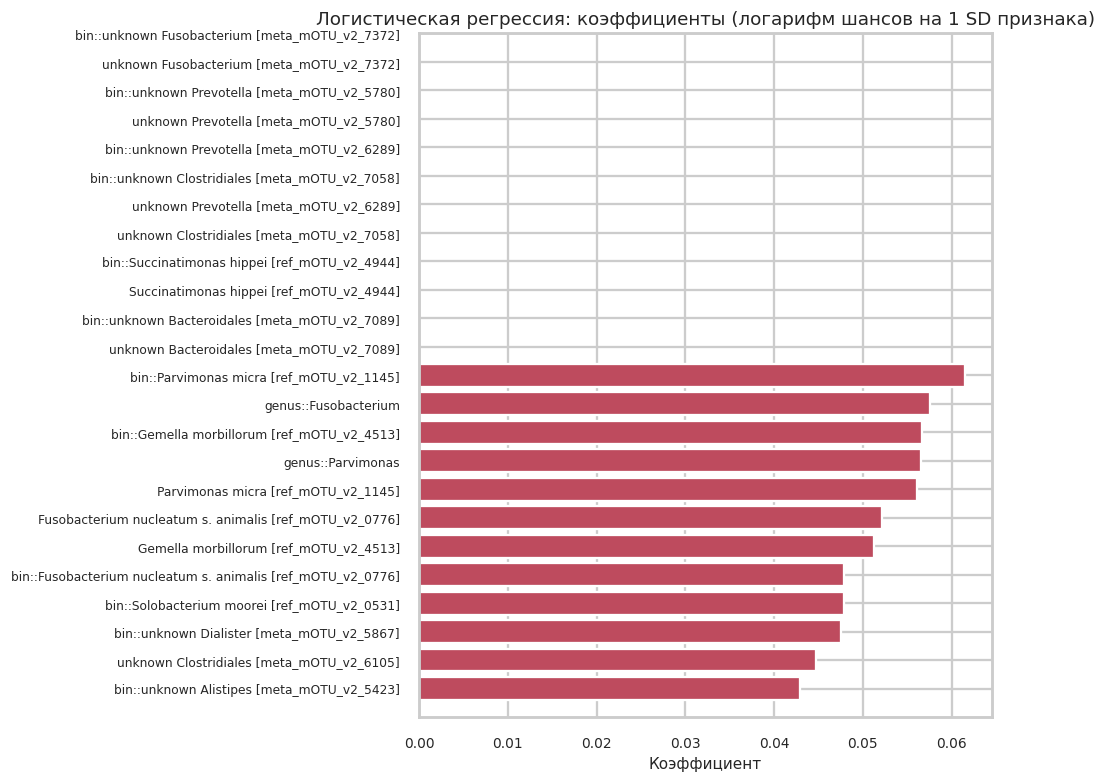

Положительный коэффициент — вклад в сторону КРР. Признаки genus:: и bin:: — агрегаты и флаги обнаружения.


In [20]:
# Коэффициенты финальной модели и их устойчивость по 25 фолдам
final_pipe = make_l2_pipeline(bac_cols, C=BEST_C).fit(train, y)
feat_names = final_pipe[:-1].get_feature_names_out()
final_coef = pd.Series(final_pipe[-1].coef_[0], index=feat_names, name='coef')

coef_df = pd.concat(coef_bank, axis=1)
coef_df.columns = [f'f{i+1}' for i in range(coef_df.shape[1])]
align = final_coef.reindex(coef_df.index)
stability = pd.DataFrame({
    'coef_full': align,
    'частота отбора': coef_df.notna().mean(axis=1),
    'согласие знака': (np.sign(coef_df).eq(np.sign(align), axis=0).sum(axis=1)
                       / coef_df.notna().sum(axis=1).replace(0, np.nan)),
    'средний coef': coef_df.mean(axis=1),
}).sort_values('coef_full', ascending=False)
display(stability.head(15).round(4))
display(stability.tail(15).round(4))

top = pd.concat([stability.head(12), stability.tail(12)])['coef_full'].sort_values()
fig, ax = plt.subplots(figsize=(9, 7), layout='constrained')
ax.barh(np.arange(len(top)), top.to_numpy(),
        color=[CLASS_COLORS[GROUP_NAMES[int(v > 0)]] for v in top])
ax.set_yticks(np.arange(len(top)), top.index, fontsize=8)
ax.axvline(0, color='.3', lw=1)
ax.set(title='Логистическая регрессия: коэффициенты (логарифм шансов на 1 SD признака)',
       xlabel='Коэффициент')
plt.show()
stability.to_csv('coef_stability.csv')
print('Положительный коэффициент — вклад в сторону КРР. Признаки genus:: и bin:: — агрегаты и флаги обнаружения.')

Пропущенный КРР (FN): реконструкция 0.247756 против OOF 0.247756
Распознанный КРР (TP): реконструкция 0.992749 против OOF 0.992749


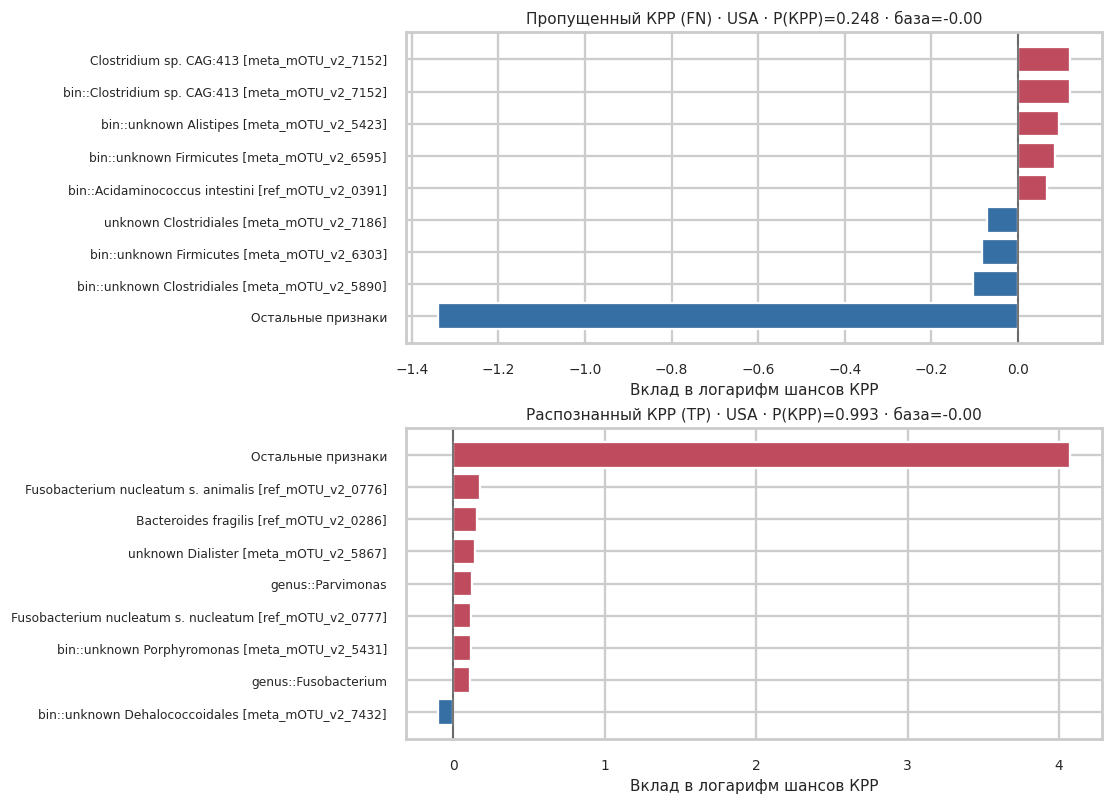

Для линейной модели разложение точное: logit = intercept + сумма coef * z.


In [21]:
# Локальное объяснение: точное разложение логита на вклады признаков (TP против FN)
worst_cohort = loco_df['AUROC'].idxmin()
pipe = loco_models[worst_cohort]
names = pipe[:-1].get_feature_names_out()
coefs, base = pipe[-1].coef_[0], float(pipe[-1].intercept_[0])

mask = (cohorts == worst_cohort) & (y == 1)
idx_pool = np.flatnonzero(mask)
p_pool = oof_loco[idx_pool]
fn_pool = idx_pool[p_pool < THR_MAIN]
tp_pool = idx_pool[p_pool >= THR_MAIN]
examples = {}
if len(fn_pool):
    examples['Пропущенный КРР (FN)'] = int(fn_pool[np.argmin(oof_loco[fn_pool])])
if len(tp_pool):
    examples['Распознанный КРР (TP)'] = int(tp_pool[np.argmax(oof_loco[tp_pool])])

fig, axes = plt.subplots(len(examples), 1, figsize=(10, 3.6 * max(len(examples), 1)),
                         squeeze=False, layout='constrained')
for ax, (title, i) in zip(axes[:, 0], examples.items()):
    z = pipe[:-1].transform(train.iloc[[i]])[0]
    contrib = pd.Series(coefs * z, index=names)
    logit = base + contrib.sum()
    strongest = contrib.loc[contrib.abs().nlargest(8).index]
    bars = pd.concat([strongest, pd.Series({'Остальные признаки': contrib.sum() - strongest.sum()})]).sort_values()
    ax.barh(np.arange(len(bars)), bars.to_numpy(),
            color=[CLASS_COLORS[GROUP_NAMES[int(v > 0)]] for v in bars])
    ax.set_yticks(np.arange(len(bars)), bars.index, fontsize=8)
    ax.axvline(0, color='.3', lw=1)
    ax.set_title(f'{title} · {worst_cohort} · P(КРР)={expit(logit):.3f} · база={base:+.2f}', fontsize=10)
    ax.set_xlabel('Вклад в логарифм шансов КРР')
    print(f'{title}: реконструкция {expit(logit):.6f} против OOF {oof_loco[i]:.6f}')
plt.show()
print('Для линейной модели разложение точное: logit = intercept + сумма coef * z.')

mOTU с q < 0.05: 143 (82 положительных, 61 отрицательных)


,rho,p,q (BH)
mOTU,,,
Parvimonas micra [ref_mOTU_v2_1145],0.45313,0.0,0.0
unknown Dialister [meta_mOTU_v2_5867],0.40969,0.0,0.0
Gemella morbillorum [ref_mOTU_v2_4513],0.39447,0.0,0.0
Fusobacterium nucleatum s. animalis [ref_mOTU_v2_0776],0.38875,0.0,0.0
Solobacterium moorei [ref_mOTU_v2_0531],0.35899,0.0,0.0
Peptostreptococcus stomatis [ref_mOTU_v2_4614],0.34267,0.0,0.0
unknown Clostridiales [meta_mOTU_v2_6105],0.31503,0.0,0.0
unknown Porphyromonas [meta_mOTU_v2_7656],0.31303,0.0,0.0
Porphyromonas uenonis [ref_mOTU_v2_4616],0.30632,0.0,0.0


,rho,p,q (BH)
mOTU,,,
Faecalibacterium prausnitzii [ref_mOTU_v2_4910],-0.18551,0.00014,0.00234
unknown Clostridiales [meta_mOTU_v2_7682],-0.18970,0.00010,0.00171
unknown Peptostreptococcaceae [meta_mOTU_v2_7331],-0.19748,0.00005,0.00099
bacterium LF-3 [ref_mOTU_v2_3608],-0.19956,0.00004,0.00086
unknown Ruminococcaceae [meta_mOTU_v2_7012],-0.20074,0.00004,0.00079
Anaerostipes hadrus [ref_mOTU_v2_1309],-0.20079,0.00004,0.00079
unknown Clostridium [meta_mOTU_v2_7530],-0.20363,0.00003,0.00065
unknown Faecalibacterium [meta_mOTU_v2_5815],-0.20848,0.00002,0.00044
unknown Clostridiales [meta_mOTU_v2_7356],-0.21277,0.00001,0.00031


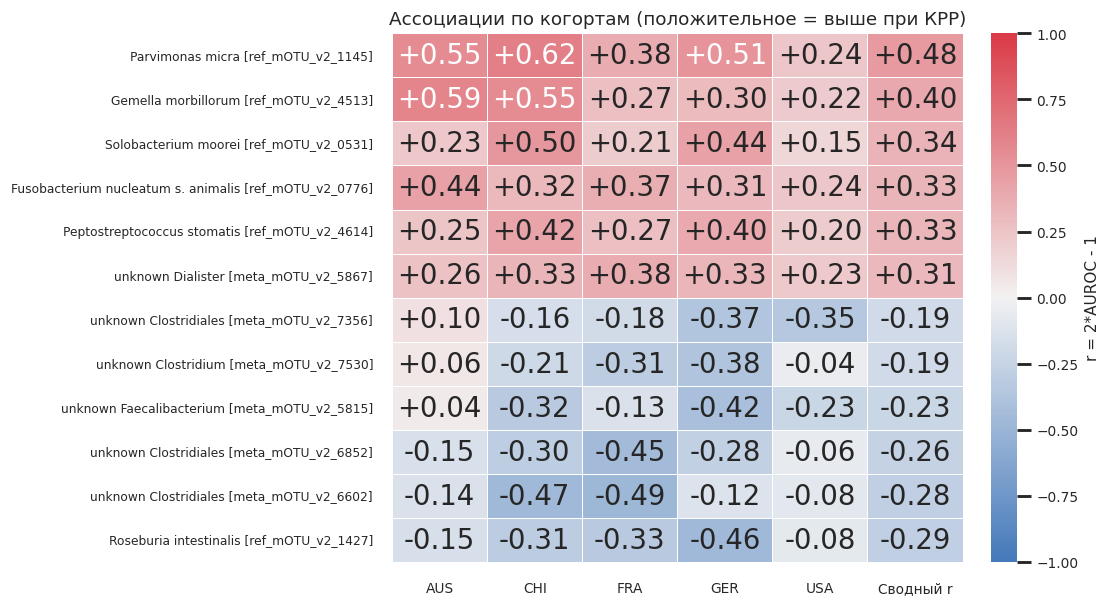

In [22]:
# Ассоциации отдельных mOTU с диагнозом: Спирмен + BH и рангово-бисериальный r по когортам
rows = []
for c in bac_cols:
    v = train[c].to_numpy()
    if np.std(v) == 0:
        continue
    rho, p = spearmanr(v, y)
    rows.append((c, rho, p))
corr = pd.DataFrame(rows, columns=['mOTU', 'rho', 'p']).set_index('mOTU')
corr['q (BH)'] = false_discovery_control(corr['p'].to_numpy())
corr = corr.sort_values('rho', ascending=False)
sig = corr[corr['q (BH)'] < 0.05]
print(f'mOTU с q < 0.05: {len(sig)} ({int((sig["rho"]>0).sum())} положительных, {int((sig["rho"]<0).sum())} отрицательных)')
display(corr.head(12).round(5)); display(corr.tail(12).round(5))

top_r = pd.concat([corr.head(6), corr.tail(6)]).index
eff, weights = {}, {}
for c in cohort_names:
    m = cohorts == c
    n1, n0 = int(y[m].sum()), int((y[m] == 0).sum())
    weights[c] = n1 * n0
    eff[c] = {t: 2 * roc_auc_score(y[m], train.loc[m, t]) - 1 for t in top_r}
eff = pd.DataFrame(eff)
summary_r = (eff * pd.Series(weights)).sum(axis=1) / sum(weights.values())
heat = eff.loc[summary_r.sort_values(ascending=False).index].assign(**{'Сводный r': summary_r})
heat = heat.sort_values('Сводный r', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.4), layout='constrained')
sns.heatmap(heat, cmap=sns.diverging_palette(250, 10, as_cmap=True), center=0, vmin=-1, vmax=1,
            annot=True, fmt='+.2f', linewidths=.5, cbar_kws={'label': 'r = 2*AUROC - 1'}, ax=ax)
ax.set(title='Ассоциации по когортам (положительное = выше при КРР)', xlabel='', ylabel='')
ax.tick_params(axis='y', labelsize=8)
plt.show()
corr.to_csv('spearman_associations.csv')

In [23]:
# Оральная панель как отдельная гипотеза (та же логистическая регрессия)
oral_summary = pd.DataFrame({'Когорта': cohorts, 'Диагноз': pd.Series(y).map(GROUP_NAMES),
                             'Суммарная доля панели, %': 100 * train['oral_total'],
                             'Обнаружено mOTU панели': train['oral_count']})
display(oral_summary.groupby('Диагноз', sort=False).median(numeric_only=True).round(5))
display(oral_summary.groupby(['Когорта', 'Диагноз']).median(numeric_only=True).round(4))
if oral_cols:
    u, p = mannwhitneyu(train.loc[y == 1, 'oral_total'], train.loc[y == 0, 'oral_total'], alternative='two-sided')
    print(f'Суммарная доля оральной панели, КРР против контроля: Mann-Whitney p = {p:.3e}')


def eval_estimator(make_model, X, n_repeats=2):
    reps = []
    with lim():
        for rep_folds in splits_5x5[:n_repeats]:
            oof = np.zeros(len(X))
            for tr, va in rep_folds:
                m = make_model()
                m.fit(X.iloc[tr], y[tr])
                oof[va] = m.predict_proba(X.iloc[va])[:, 1]
            reps.append(oof)
        oof_m = np.mean(reps, axis=0)
        loco = np.zeros(len(X))
        for tr, va in loco_splits:
            m = make_model()
            m.fit(X.iloc[tr], y[tr])
            loco[va] = m.predict_proba(X.iloc[va])[:, 1]
    return {'repeat_mean': float(np.mean([roc_auc_score(y, o) for o in reps])),
            'oof_auc': roc_auc_score(y, oof_m),
            'per_cohort_auc': per_cohort_auc(y, oof_m, cohorts),
            'loco_auc': roc_auc_score(y, loco),
            'loco_macro': per_cohort_auc(y, loco, cohorts)}


oral_X = train[oral_cols + ['oral_total', 'oral_count']].copy()
oral_X['oral_total'] = np.log1p(oral_X['oral_total'] * 1e6)
res_oral = eval_estimator(lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.004, max_iter=5000)), oral_X)
display(pd.DataFrame([{'Признаки': 'Оральная панель', **res_oral},
                      {'Признаки': 'Полный mOTU-профиль (рабочая модель)',
                       'repeat_mean': float(np.mean(rep_aucs)), 'oof_auc': roc_auc_score(y, oof_mean),
                       'per_cohort_auc': per_cohort_auc(y, oof_mean, cohorts),
                       'loco_auc': roc_auc_score(y, oof_loco),
                       'loco_macro': per_cohort_auc(y, oof_loco, cohorts)}]).set_index('Признаки').round(4))

,"Суммарная доля панели, %",Обнаружено mOTU панели
Диагноз,,
Контроль,0.00787,1.0
КРР,0.04741,4.0


Суммарная доля панели, %  Обнаружено mOTU панели
Когорта Диагноз                                                   
AUS     КРР                         0.0411                     3.0
        Контроль                    0.0095                     1.0
CHI     КРР                         0.1075                     4.5
        Контроль                    0.0000                     0.0
FRA     КРР                         0.0589                     4.0
        Контроль                    0.0223                     3.0
GER     КРР                         0.0424                     4.0
        Контроль                    0.0000                     0.0
USA     КРР                         0.0165                     1.5
        Контроль                    0.0047                     1.0

Суммарная доля оральной панели, КРР против контроля: Mann-Whitney p = 6.564e-22


,repeat_mean,oof_auc,per_cohort_auc,loco_auc,loco_macro
Признаки,,,,,
Оральная панель,0.7680,0.7648,0.7602,0.7428,0.7692
Полный mOTU-профиль (рабочая модель),0.8966,0.9034,0.8936,0.8661,0.8634


ValueError: not enough values to unpack (expected 3, got 2)

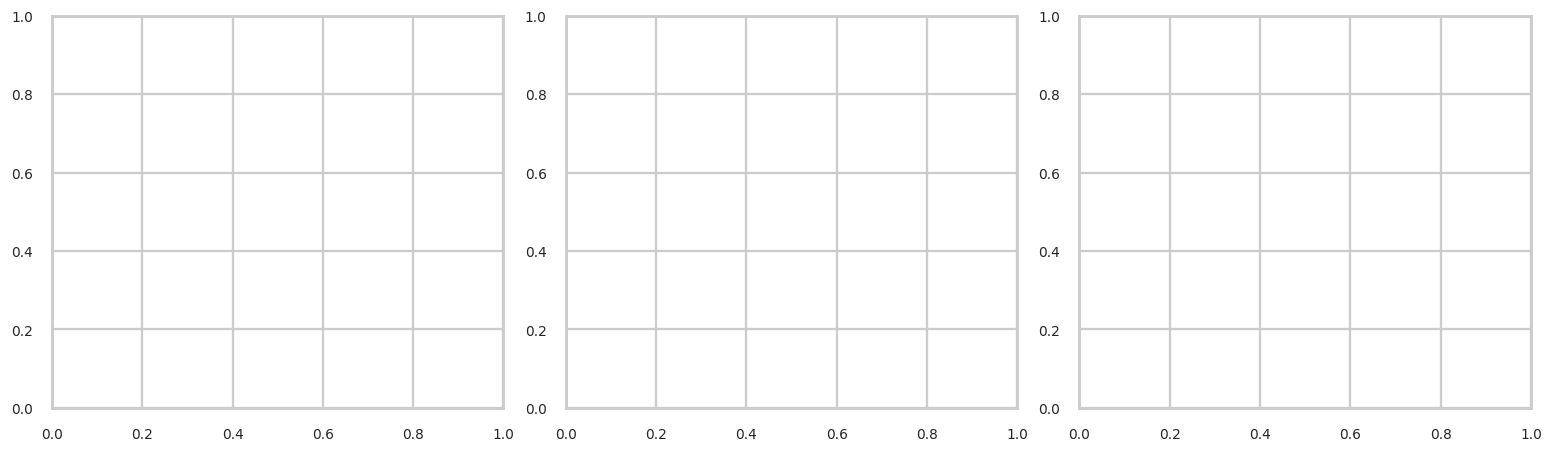

In [24]:
# Альфа-разнообразие (на нормированных долях)
profiles = train_rel
alpha = pd.DataFrame({
    'Шеннон': -(profiles * np.log(profiles.where(profiles > 0, 1))).sum(axis=1),
    'Симпсон (1-D)': 1 - profiles.pow(2).sum(axis=1),
    'Обнаружено mOTU': (train[bac_cols] > 0).sum(axis=1),
})
rows, fig, axes = [], plt.subplots(1, 3, figsize=(14, 4), layout='constrained')
for ax, metric in zip(axes, alpha.columns):
    a, b = alpha.loc[y == 0, metric], alpha.loc[y == 1, metric]
    _, p = mannwhitneyu(a, b, alternative='two-sided')
    rows.append({'Метрика': metric, 'Контроль, медиана': a.median(), 'КРР, медиана': b.median(), 'p': p})
    sns.boxplot(x=pd.Series(cohorts), y=alpha[metric], hue=pd.Series(y).map(GROUP_NAMES),
                palette=CLASS_COLORS, ax=ax, fliersize=2)
    ax.set(title=f'{metric} · p={p:.2g}', xlabel='Когорта'); ax.legend(title='')
plt.show()
display(pd.DataFrame(rows).set_index('Метрика').round(5))
print('Разнообразие сильно зависит от когорты: межгрупповой сигнал без учёта когорты легко переоценить.')

In [ ]:
# Bray-Curtis: PCoA, PERMANOVA с поправкой на когорту, проверка разброса
D = cdist(train_rel.to_numpy(), train_rel.to_numpy(), metric='braycurtis')
n = len(D)
J = np.eye(n) - np.ones((n, n)) / n
G = -0.5 * J @ (D ** 2) @ J
G = (G + G.T) / 2

eigvals, eigvecs = np.linalg.eigh(G)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
pos_eig = eigvals[eigvals > 0]
neg_share = 100 * np.abs(eigvals[eigvals < 0]).sum() / pos_eig.sum()
coords = eigvecs[:, :2] * np.sqrt(np.maximum(eigvals[:2], 0))
pct = 100 * eigvals[:2] / pos_eig.sum()
print(f'Отрицательных собственных значений: {int((eigvals < 0).sum())}, их модули = {neg_share:.1f}% суммы положительных')

pcoa = pd.DataFrame({'PCoA1': coords[:, 0], 'PCoA2': coords[:, 1],
                     'Диагноз': pd.Series(y).map(GROUP_NAMES), 'Когорта': cohorts})
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True, layout='constrained')
sns.scatterplot(data=pcoa, x='PCoA1', y='PCoA2', hue='Диагноз', palette=CLASS_COLORS, alpha=.75, s=28, ax=axes[0])
sns.scatterplot(data=pcoa, x='PCoA1', y='PCoA2', hue='Когорта', palette='Set2', alpha=.75, s=28, ax=axes[1])
for ax, t in zip(axes, ['PCoA по диагнозу', 'PCoA по когорте']):
    ax.set(title=t, xlabel=f'PCoA1 · {pct[0]:.1f}%', ylabel=f'PCoA2 · {pct[1]:.1f}%')
    ax.set_aspect('equal', adjustable='box')
plt.show()


def permanova_adjusted(labels, groups, n_perm=N_PERM, seed=SEED):
    Z = pd.get_dummies(pd.Series(groups), dtype=float).to_numpy()
    Q, _ = np.linalg.qr(Z)
    R = np.eye(len(labels)) - Q @ Q.T
    ss_total = float(np.trace(G))
    ss_after = ss_total - float(np.trace((Q @ Q.T) @ G))
    u = R @ labels.astype(float)
    ss_lab = float(u @ G @ u) / float(u @ u)
    df_resid = len(labels) - Z.shape[1] - 1
    f_obs = (ss_lab / 1) / ((ss_after - ss_lab) / df_resid)
    rng = np.random.default_rng(seed)
    cnt = 0
    for _ in range(n_perm):
        yp = labels.copy()
        for g in np.unique(groups):
            m = groups == g
            yp[m] = rng.permutation(labels[m])
        up = R @ yp.astype(float)
        ssp = float(up @ G @ up) / float(up @ up)
        cnt += int(ssp >= ss_lab - 1e-12)
    return f_obs, ss_lab / ss_after, (1 + cnt) / (n_perm + 1)


with lim():
    f_obs, r2, p_perm = permanova_adjusted(y, cohorts)
print(f'PERMANOVA (диагноз | когорта): псевдо-F {f_obs:.4f}, частичный R2 {r2:.4f} ({r2:.2%}), p {p_perm:.4f}')

rows = []
rng = np.random.default_rng(SEED)
for c in cohort_names:
    idx = np.flatnonzero(cohorts == c)
    lab = y[idx]
    out = {}
    for cls in [0, 1]:
        sel = lab == cls
        block = G[np.ix_(idx[sel], idx[sel])]
        d2 = np.diag(block) - 2 * block.mean(axis=1) + block.mean()
        ng = int(sel.sum())
        out[cls] = np.sqrt(np.maximum(d2, 0) * ng / (ng - 1))
    d_all = np.concatenate([out[0], out[1]])
    lab_all = np.concatenate([np.zeros(len(out[0])), np.ones(len(out[1]))])
    obs = abs(out[1].mean() - out[0].mean())
    cnt = 0
    for _ in range(N_PERM):
        perm = rng.permutation(d_all)
        cnt += int(abs(perm[lab_all == 1].mean() - perm[lab_all == 0].mean()) >= obs - 1e-12)
    rows.append({'Когорта': c, 'Контроль, среднее d': out[0].mean(), 'КРР, среднее d': out[1].mean(),
                 'p': (1 + cnt) / (N_PERM + 1)})
disp = pd.DataFrame(rows).set_index('Когорта')
disp['q (BH)'] = false_discovery_control(disp['p'].to_numpy())
display(disp.round(4))
print('PERMANOVA реагирует и на сдвиг центра, и на разброс: различие дисперсий отмечено при q < 0.05.')

In [ ]:
# Метаданные отдельно и вместе с микробиомом (модель та же — L2-логистика)
meta_prep = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), meta_num),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first'), meta_cat),
])
meta_X = train[meta_num + meta_cat].copy()

res_meta = eval_estimator(lambda: make_pipeline(meta_prep, LogisticRegression(C=1.0, max_iter=5000)), meta_X)


def make_combined(C=BEST_C):
    pre = ColumnTransformer([
        ('bac', make_pipeline(TaxaFeatures(bac_cols, MIN_PREVALENCE, 'log10', eps=LOG_EPS), StandardScaler()), bac_cols),
        ('meta', meta_prep, meta_num + meta_cat),
    ])
    return make_pipeline(pre, LogisticRegression(C=C, solver='lbfgs', max_iter=5000, random_state=SEED))


res_comb = eval_estimator(make_combined, train)
display(pd.DataFrame([{'Набор': 'Только метаданные', **res_meta},
                      {'Набор': 'mOTU (рабочая модель)', 'repeat_mean': float(np.mean(rep_aucs)),
                       'oof_auc': roc_auc_score(y, oof_mean),
                       'per_cohort_auc': per_cohort_auc(y, oof_mean, cohorts),
                       'loco_auc': roc_auc_score(y, oof_loco),
                       'loco_macro': per_cohort_auc(y, oof_loco, cohorts)},
                      {'Набор': 'mOTU + метаданные', **res_comb}]).set_index('Набор').round(4))
print('Метаданные сами по себе почти не разделяют классы; добавление к mOTU обычно не улучшает перенос на новую когорту.')

In [ ]:
# Adversarial validation: насколько test отличается от train
adv_X = np.vstack([
    np.log10(np.clip(train[bac_cols].to_numpy(), 0, None) + LOG_EPS),
    np.log10(np.clip(test[bac_cols].to_numpy(), 0, None) + LOG_EPS),
])
adv_meta_tr = train[meta_num].fillna(train[meta_num].median()).to_numpy()
adv_meta_te = test[meta_num].fillna(train[meta_num].median()).to_numpy()
adv_X = np.hstack([adv_X, np.vstack([adv_meta_tr, adv_meta_te])])
adv_names = bac_cols + meta_num
y_adv = np.r_[np.zeros(len(train)), np.ones(len(test))]

oof_adv = np.zeros(len(y_adv))
coefs_adv = np.zeros(adv_X.shape[1])
skf_adv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
with lim():
    for tr, va in skf_adv.split(adv_X, y_adv):
        m = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000))
        m.fit(adv_X[tr], y_adv[tr])
        oof_adv[va] = m.predict_proba(adv_X[va])[:, 1]
        coefs_adv += m[-1].coef_[0] / 5
print(f'Adversarial AUC (train против test): {roc_auc_score(y_adv, oof_adv):.4f}')
print('Около 0.5 — распределения совпадают; заметно выше 0.7 — есть технический сдвиг, порогам верить осторожнее.')
display(pd.DataFrame({'feature': adv_names, 'coef': coefs_adv,
                      'abs': np.abs(coefs_adv)}).sort_values('abs', ascending=False).head(10).round(4))

In [ ]:
# Абляции конфигураций L2 (2 повтора 5-fold + LOCO). Отбор по LOCO, а не по pooled OOF.
configs = [('база: p03 log10 C=0.004', {})]
for pv in [0.02, 0.05, 0.10]:
    configs.append((f'встречаемость {int(pv*100)}%', {'min_prevalence': pv}))
for meth in ['sqrt', 'clr', 'raw']:
    configs.append((f'преобразование {meth}', {'method': meth}))
for c_val in [0.001, 0.002, 0.01, 0.03]:
    configs.append((f'C={c_val}', {'C': c_val}))
configs += [('без genus-агрегатов', {'add_genus': False}),
            ('без бинарных флагов', {'add_binary': False}),
            ('только log10 mOTU', {'add_genus': False, 'add_binary': False})]

rows = []
for name, kw in configs:
    res = eval_estimator(lambda kw=kw: make_l2_pipeline(bac_cols, **{**{'C': BEST_C}, **kw}), train, n_repeats=2)
    rows.append({'Конфигурация': name, **res})
abl = pd.DataFrame(rows).set_index('Конфигурация').sort_values('loco_auc', ascending=False)
display(abl.round(4))
abl.to_csv('ablations_l2.csv')
print('Перебор конфигураций на тех же данных даёт оптимизм отбора: разница в 0.005-0.01 AUROC не значима.')

In [ ]:
# Разбор ошибок при рабочем пороге на честных LOCO-прогнозах
pred_pos = oof_loco >= THR_MAIN
grp = np.where((y == 1) & pred_pos, 'TP', np.where((y == 1) & ~pred_pos, 'FN',
        np.where((y == 0) & pred_pos, 'FP', 'TN')))
err = pd.DataFrame({'Группа': grp, 'Когорта': cohorts, 'P(КРР)': oof_loco,
                    'oral_total, %': 100 * train['oral_total'].to_numpy(),
                    'oral_count': train['oral_count'].to_numpy(),
                    'Шеннон': alpha['Шеннон'].to_numpy(),
                    'Обнаружено mOTU': alpha['Обнаружено mOTУ'].to_numpy() if 'Обнаружено mOTУ' in alpha else alpha['Обнаружено mOTU'].to_numpy(),
                    'age': train['age'].to_numpy() if 'age' in train else np.nan,
                    'bmi': train['bmi'].to_numpy() if 'bmi' in train else np.nan})
display(err.groupby('Группа').median(numeric_only=True).round(4))
display(pd.crosstab(err['Когорта'], err['Группа']))

if (grp == 'FN').sum() > 2 and (grp == 'TP').sum() > 2:
    rows = []
    for col in ['oral_total, %', 'oral_count', 'Шеннон', 'Обнаружено mOTU', 'age', 'bmi']:
        a, b = err.loc[grp == 'FN', col].dropna(), err.loc[grp == 'TP', col].dropna()
        if len(a) > 2 and len(b) > 2:
            _, p = mannwhitneyu(a, b, alternative='two-sided')
            rows.append({'Признак': col, 'FN медиана': a.median(), 'TP медиана': b.median(), 'p': p})
    display(pd.DataFrame(rows).set_index('Признак').round(5))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout='constrained')
for ax, col in zip(axes, ['oral_total, %', 'Шеннон', 'P(КРР)']):
    sns.boxplot(data=err, x='Группа', y=col, order=['TN', 'FP', 'FN', 'TP'], palette='Set2', ax=ax, fliersize=2)
    ax.set(title=f'{col} по группам ошибок', xlabel='')
plt.show()

worst_fn = err[err['Группа'] == 'FN'].nsmallest(8, 'P(КРР)')
display(worst_fn.round(4))
print('Пропущенные КРР — кандидаты на "серую зону": низкая оральная нагрузка и профиль, близкий к контролю.')

In [ ]:
final_full = make_l2_pipeline(bac_cols, C=BEST_C).fit(train, y)
full_test_probs = final_full.predict_proba(test)[:, 1]
pd.DataFrame({'sample_id': test['sample_id'], 'label': full_test_probs}).to_csv('sub_fulltrain_l2.csv', index=False)

print('ИТОГОВЫЕ МЕТРИКИ (L2, log10, p>=3%, genus+binary, C=%.4f)' % BEST_C)
print(f'  repeat_mean    {np.mean(rep_aucs):.4f}')
print(f'  oof_auc        {roc_auc_score(y, oof_mean):.4f}')
print(f'  per_cohort_auc {per_cohort_auc(y, oof_mean, cohorts):.4f}')
print(f'  loco_auc       {roc_auc_score(y, oof_loco):.4f}')
print(f'  fold_std       {np.std(fold_aucs):.4f}')
print(f'\nПороги: скрининг {THR_MAIN:.3f} (Se>={TARGET_SENS}), подтверждение {THR_RULEIN:.3f} (Sp>={TARGET_SPEC}), Youden {THR_YOUDEN:.3f}')
s = confusion_stats(y, oof_loco, THR_MAIN)
print(f'LOCO при рабочем пороге: TP {s["TP"]}, FN {s["FN"]}, FP {s["FP"]}, TN {s["TN"]} | Se {s["sens"]:.3f} | Sp {s["spec"]:.3f}')
print('\nФайлы: sub_best_l2_bin.csv (сабмит), sub_fulltrain_l2.csv, test_predictions_thresholds.csv,')
print('       oof_predictions.csv, threshold_sweep_oof.csv, threshold_rules.csv, coef_stability.csv,')
print('       spearman_associations.csv, ablations_l2.csv, cv_fold_metrics.csv')
print('\nВерсии:', ' · '.join(f'{p}=={version(p)}' for p in
      ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn']))